# Temperature at the algorithm-deciding token: a CPU demo of the K1/HR experiment

**Is temperature the LLM "creativity knob"?** When bf16 **Qwen3-8B** writes code for a task such as *connected
components*, it commits to an algorithm at one or two generated tokens. Right after `def solve(n, edges):` it writes
` parent` (union-find, 94%) or ` def` (then ` find` → union-find, or ` dfs` → DFS).

This experiment (iteration 8, claims **K1** and **HR**) applies temperature **only at that decision token**: T = d over
its 20 most probable candidates, and T = 1 everywhere else. The dose d is **committed in advance** from the token's
teacher-forced logits plus a *token map* (10 forced continuations per candidate, each labelled by algorithm and run
against hidden tests). The "fork dose" is compared with the standard knobs, all on the same 50 common-random-number
(CRN) streams per unit, so every slot sees the same random numbers in every arm:

- global T 1.3 / 1.6 / 2.0 with top-p 0.95;
- min-p 0.1 at T 3;
- EDT- and AdapT-style temperature;
- the same dose at the highest-entropy or a random position;
- class-uniform forcing of the decision token.

**What this notebook runs** (CPU only, about a minute): the CPU half of the original pipeline, on the original run's
programs for two units:
- **T10**, connected components: the *collapsed* unit (the T = 1 "twin" writes union-find 50/50);
- **B6**, valid anagram: a *mixed* unit (sort-and-compare 40, fixed 26-slot count array 8, hash map 2).

| step | original module | what it does |
|---|---|---|
| COMMIT #1 | `src/dose8.py`, `src/predict8.py`, `src/commit8.py` | token maps → composed algorithm shares at every dose → dose table d1/d2 → per-arm and per-slot replay predictions, hash-committed |
| K1 scoring | `src/analysis_k1.py` | observed shares, pass rate, correct-only Hill-1, Newcombe CIs, McNemar, paired slot bootstrap, verdicts |
| COMMIT #3 | `src/amend8.py`, `src/amend_analysis8.py` | the amendment: the same dose with the program-breaking candidates removed |
| HR | `src/hr8.py` | ideas reachable only by forcing the decision token's top-64 branches, and how many T = 1 samples away they are |
| figures | `src/figures8.py` | F1 dose-response, F2 quality-diversity, F3 entropy, F4 token maps, F5 HR maps, F7 flip matrices, F8 activation geometry |

**What it does not run:** the GPU stages (`src/gpu8.py`, `src/engine8.py`: decoding with bf16 Qwen3-8B, 2.8 GPU-hours
on an NVIDIA L4). Their outputs (programs, decision-token logits, entropies, hidden states) come from the original run
through `mini_demo_data.json`. `method.py`, the artifact's entry point, is a stage runner that calls these modules
in order; it is shown below for reference.

**Arms:** A0 twin (T = 1) · A1 / A2 / A3g global T 1.3 / 1.6 / 2.0 (+ top-p 0.95) · A4 min-p 0.1 at T 3 · A5 EDT-style ·
A6 AdapT-style · A7 dose at the entropy-max position · A8 dose at a random position · **A9 / A10 fork dose d1 / d2** ·
A11 class-uniform forcing · A9f / A10f the amendment (filtered fork dose).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original modules log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# ---- the original modules' imports (method.py, cfg8, predict8, units8, dose8, commit8, analysis_k1, hr8, figures8)
import base64
import glob
import hashlib
import io
import json
import keyword
import math
import os
import re
import resource
import shutil
import subprocess
import sys
import time
import tokenize
from collections import Counter, defaultdict
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from loguru import logger
from scipy import stats

# ---- notebook additions: inline plots (figures8 used the non-interactive Agg backend), tables, module stand-ins
import matplotlib.pyplot as plt
import pandas as pd
import warnings
from types import SimpleNamespace

warnings.filterwarnings("ignore", message=r"Glyph \d+ .*missing from font")   # T10's candidate token '父' (no CJK font)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-8/experiment-39/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
ex = data["datasets"][0]["examples"]
print(data["metadata"]["title"])
print(f'{len(ex)} examples (unit x CRN slot) holding {sum(len(e["samples"]) for e in ex)} programs; '
      f'{len(data["unit_resources"]["continuations"])} token-map / HR continuations')
print("first example:", ex[0]["input"], "->", ex[0]["output"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Temperature at the algorithm-deciding token (iteration 8, claims K1 and HR) - demo subset
100 examples (unit x CRN slot) holding 1200 programs; 1315 token-map / HR continuations
first example: unit T10 (connected components, Qwen3-8B bf16); prompt template W1; CRN slot 0 (stream key ['T10', 'W1', 0]); 14 programs from the same uniform stream (twin + arms) -> union_find|pass


## Configuration

Every runtime knob is set here. The analysis is deterministic given the data: the seeds are fixed (bootstrap
20261023, noise ceiling 20261023). With the original values (in the comments) the notebook reproduces the
artifact's stored numbers, and the last cell checks this. Fewer bootstrap replicates change only the bootstrap lower
bounds and p-values, and fewer noise draws change only the noise-ceiling estimate.

In [5]:
# The demo data holds two units: T10 (collapsed) and B6 (mixed). The original run analysed T10, T1, B3, A3, B6, T2,
# T03 (Qwen3-8B) and G (Gemma-3-4b-it).
UNITS_TO_RUN = ["T10", "B6"]   # original: every unit; demo data: ["T10", "B6"]
N_BOOT = 2000                 # paired slot-bootstrap replicates, K1(b) and the amendment (original: 2000)
NOISE_DRAWS = 10_000           # multinomial draws, MAE noise ceiling over all dosed cells (original: 10_000)
NOISE_DRAWS_UNIT = 4000         # the same per unit (original: 4000)
F2_BOOT = 200                  # bootstrap draws per arm for the F2 uncertainty ellipses (original: 200)
WORKDIR = "k1_demo_run"        # local folder where the original file layout is rebuilt and results are written

## The entry point: `method.py`

`method.py` is a stage runner: each stage is a subprocess call of a module in `src/`.
- **GPU stages** decode with bf16 Qwen3-8B / Gemma-3-4b-it: `s0` twins, `s2` token maps, `s3` arms, `s4` HR
  branches, `s1` blind locator, `s3x` amendment arms.
- **Commit stages** hash-commit the predictions before the samples they predict.
- **`analyse`** scores everything on a CPU.

The cell below is the original file. Its `main()` is defined but not called, because it would start the label daemon
and the GPU jobs. The cell then prints which stages this notebook re-runs.

In [6]:
# ===== method.py =====
"""Temperature at one deciding token (iteration 8, claims K1 and HR): entry point running every stage in order.

The method: temperature applied ONLY at a located decision token (T = d with top-20 there, T = 1 everywhere else),
with d committed in advance from that token's teacher-forced logits and a token map of forced continuations.
The baselines/comparators, run on the same 50 common-random-number slot streams per unit: global temperature
1.3 / 1.6 / 2.0 with top-p 0.95, min-p 0.1 at T 3.0, EDT-style and AdapT-style per-token temperature, the
highest-entropy position and a random position at the same dose (placebos), and class-uniform forcing.

Stages (each resumes from its files; GPU stages run one model per process):
  vendor      copy and hash every prior input into inputs/                       (src/vendor_inputs.py)
  prompts     Gemma twin prompt ids (exp38 prompt code, run once)                   (scripts/build_gemma_prompts.sh)
  labeller    background label daemon (frozen labellers)                           (src/label_daemon.py)
  cputests    C1-C6                                                                (src/tests8.py cpu)
  commit0     protocol.json                                                        (src/protocol8.py, commit8.py)
  s0          twins + GPU tests U1-U8, Qwen then Gemma                             (src/gpu8.py <model> s0)
  gputests    evaluate U1-U8 -> identity-shortcut flag                             (src/tests8.py gpu)
  s2          token maps (Qwen, then Gemma)                                        (src/gpu8.py <model> s2)
  commit1     dose table and every committed prediction                            (src/make_commits.py c1)
  commit2     HR predictions and novelty-audit protocol                            (src/make_commits.py c2)
  s3          arms (Gemma, Qwen)                                                    (src/gpu8.py <model> s3)
  s4          HR branches                                                          (src/gpu8.py <model> s4)
  s1          blind locator (T10, B3); COMMIT #1b is its verdict                    (src/gpu8.py qwen s1)
  commit3     adjudication + the pass-filtered-dose amendment (COMMIT #3)           (src/amend8.py)
  s3x         amendment arms A9f/A10f on T10 and G                                 (src/gpu8.py <model> s3x)
  analyse     adjudication, stage-0 report, K1 analysis, amendment, HR, locator, novelty audit, tables, figures,
              outputs, stdlib audit
Usage: .venv/bin/python method.py all | <stage>[,<stage>...]
"""

ROOT = Path(WORKDIR).resolve()                     # [notebook] original: Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
QWEN_UNITS = "T10,B3,T1,A3,B6"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(parents=True, exist_ok=True)   # [notebook] parents=True: WORKDIR is new
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STEPS: dict[str, list[list[str]]] = {
    "vendor": [[PY, "src/vendor_inputs.py"]],
    "prompts": [["bash", "scripts/build_gemma_prompts.sh"]],
    "cputests": [[PY, "src/tests8.py", "cpu"]],
    "commit0": [[PY, "src/protocol8.py"],
                [PY, "src/commit8.py", "commit", "COMMIT0_protocol", "predictions/protocol.json", "src/cfg8.py",
                 "src/engine8.py", "src/predict8.py", "src/units8.py", "src/gpu8.py", "src/stages8.py"]],
    "s0": [[PY, "src/gpu8.py", "qwen", "s0"], [PY, "src/gpu8.py", "gemma", "s0"]],
    "gputests": [[PY, "src/stage0_report.py"], [PY, "src/tests8.py", "gpu"]],
    "s2": [[PY, "src/gpu8.py", "qwen", "s2", "--units", QWEN_UNITS], [PY, "src/gpu8.py", "gemma", "s2"]],
    "commit1": [[PY, "src/make_commits.py", "c1"]],
    "commit2": [[PY, "src/make_commits.py", "c2"]],
    "s3": [[PY, "src/gpu8.py", "gemma", "s3,s4"], [PY, "src/gpu8.py", "qwen", "s3,s4", "--units", "T10,B3"],
           [PY, "src/gpu8.py", "qwen", "s3", "--units", "B6,T2,T03,T1,A3"]],
    "s1": [[PY, "src/gpu8.py", "qwen", "s1", "--units", "T10,B3"]],
    "s4": [[PY, "src/gpu8.py", "qwen", "s4", "--units", "B6,A3"], [PY, "src/gpu8.py", "qwen", "s3", "--units", "A3"]],
    "commit3": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/amend8.py"]],
    "s3x": [[PY, "src/gpu8.py", "qwen", "s3x", "--units", "T10"], [PY, "src/gpu8.py", "gemma", "s3x", "--units", "G"]],
    "analyse": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/stage0_report.py"], [PY, "src/analysis_k1.py"],
                [PY, "src/amend_analysis8.py"], [PY, "src/hr8.py"], [PY, "src/locator8.py"],
                [PY, "src/novelty8.py", "index"], [PY, "src/novelty8.py", "audit"], [PY, "src/report8.py"],
                [PY, "src/finalize8.py"]],
}
ORDER = ["vendor", "prompts", "cputests", "commit0", "s0", "gputests", "s2", "commit1", "commit2", "s1", "s3", "s4",
         "commit3", "s3x", "analyse"]


@logger.catch(reraise=True)
def main() -> None:
    req = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if req == "all" else req.split(",")
    labeller = None
    if any(s in ("s0", "s2", "s3", "s4", "s1") for s in stages):
        labeller = subprocess.Popen([PY, "src/label_daemon.py"], cwd=ROOT)
        logger.info(f"label daemon pid {labeller.pid}")
    try:
        for st in stages:
            for cmd in STEPS[st]:
                t0 = time.time()
                logger.info(f"[{st}] {' '.join(cmd[1:])}")
                r = subprocess.run(cmd, cwd=ROOT)
                if r.returncode != 0:
                    logger.error(f"[{st}] failed with exit code {r.returncode}")
                    raise SystemExit(r.returncode)
                logger.info(f"[{st}] done in {time.time() - t0:.0f}s")
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=3600)


# [notebook] main() is not called. What happens to each stage here:
IN_NOTEBOOK = {
    "src/dose8.py": "COMMIT #1 table: re-run below (dose8.build_commit1)",
    "src/make_commits.py": "COMMIT #1 re-run below (c1); c2 is a text protocol, not re-run",
    "src/commit8.py": "hash chain: re-run below (fresh chain in WORKDIR)",
    "src/amend8.py": "COMMIT #3 amendment: re-run below",
    "src/analysis_k1.py": "re-run below",
    "src/amend_analysis8.py": "re-run below",
    "src/hr8.py": "re-run below",
    "src/gpu8.py": "GPU decoding: its rows ship in mini_demo_data.json",
    "src/novelty8.py": "judge adjudication / novelty audit: adjudicated labels ship in the data",
}
for st in ORDER:
    for cmd in STEPS[st]:
        script = cmd[1]
        print(f"{st:9s} {' '.join(cmd[1:])[:60]:60s} -> {IN_NOTEBOOK.get(script, 'not run in this demo')}")

vendor    src/vendor_inputs.py                                         -> not run in this demo
prompts   scripts/build_gemma_prompts.sh                               -> not run in this demo
cputests  src/tests8.py cpu                                            -> not run in this demo
commit0   src/protocol8.py                                             -> not run in this demo
commit0   src/commit8.py commit COMMIT0_protocol predictions/protocol. -> hash chain: re-run below (fresh chain in WORKDIR)
s0        src/gpu8.py qwen s0                                          -> GPU decoding: its rows ship in mini_demo_data.json
s0        src/gpu8.py gemma s0                                         -> GPU decoding: its rows ship in mini_demo_data.json
gputests  src/stage0_report.py                                         -> not run in this demo
gputests  src/tests8.py gpu                                            -> not run in this demo
s2        src/gpu8.py qwen s2 --units T10,B3,T1,A3,B6   

## `src/cfg8.py`: constants and file layout

Every module imports its constants from `cfg8`; in the notebook they are plain globals. The one change is that `ROOT`
points to a local working folder (`WORKDIR`). A later cell writes the original run's files there from
`mini_demo_data.json`, so the original readers (`read_jsonl`, `read_json`, `Path.exists`) work unchanged.

In [7]:
# ===== src/cfg8.py =====
"""Iteration-8 claim K1/HR constants: temperature applied only at located decision tokens (bf16 Qwen3-8B, thinking
off; bf16 Gemma-3-4b-it on the grid task).

Conventions (inherited from iterations 5-7, see README.md):
- A UNIT is (model, task, 5 prompt templates W1-W5, 10 CRN slots per template) = 50 slots s = 0..49 with
  template W_{s // 10 + 1} and source slot j = s % 10. Each slot owns one uniform stream (PCG64 of stable_seed(ukey))
  that every arm reuses, one uniform per generated token (the coupling that makes per-slot flips exact).
  Slot keys are the source artifacts' own keys, so Stage 0 twins re-generate exactly their T = 1 programs:
    T10/T1/T2/T03 (exp34/exp35 iteration-6 keys)      ukey = (unit, W, j)
    B3/A3/B6 (exp35 same-seed sweep streams)          ukey = ('iter7T', unit, W, 20 + j)
    G (Gemma grid, exp38 G3 sweep streams)            ukey = ('iter7GG3', 'T1', W, j)
- Sampler (Qwen, engine5 numerics): float64 softmax(logits / T) -> truncation masks -> inverse CDF over the FULL
  vocabulary in token-id order (searchsorted of the row's uniform). Gemma uses exp38's numerics (float32 softmax,
  float64 cumsum). Truncation never renormalises before the inverse CDF (the CDF is divided by the kept mass).
- A decision node n = (opening P_n, index i_n = |P_n|); the DOSE is (T_d, top-20) applied at generated index i_n
  only, T = 1 everywhere else.
"""

ROOT = Path(WORKDIR).resolve()                     # [notebook] original: Path(__file__).resolve().parents[1]
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
PROMPTS_DIR = ROOT / "prompts"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, PROMPTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

COMMITS = ROOT / "commitments.log"
SAMPLES = DATA_DIR / "samples.jsonl"            # every generated program (all stages/arms), one row per program
LABELS = DATA_DIR / "labels.jsonl"              # one label row per program (keyed by sid)
CONTS = DATA_DIR / "continuations.jsonl"        # locator / token-map / HR continuations
CONT_LABELS = DATA_DIR / "continuation_labels.jsonl"
STEPLOG = DATA_DIR / "steplog.jsonl"            # per-row decision logits, entropies, decision positions
TIMING = RESULTS_DIR / "timing.jsonl"

I6_SRC = INPUTS / "iter6_exp30" / "src"
E35 = INPUTS / "exp35"
E34 = INPUTS / "exp34"
E38 = INPUTS / "exp38"

# the declared dataset dependency art_j3Rm_lr2nzR6 (full_data_out.json): published as a sibling folder of this one;
# ART_J3RM_DIR overrides it (used on the original server, where the dependency lives in another run's folder)
DEP_DIR = Path(os.environ.get("ART_J3RM_DIR") or (ROOT.parent / "art_j3Rm_lr2nzR6"))

### Models, units and CRN slot streams

A **unit** is one model, one task, 5 prompt templates (W1-W5) and 10 slots per template: 50 slots. Each slot owns one
stream of uniforms (`u_stream(*slot_ukey(unit, s))`, a PCG64 generator seeded by a sha256 of the key), and *every* arm
decodes with the same uniforms, one per generated token. This coupling makes every comparison paired per slot: an arm
that leaves a slot's decision token unchanged sees the same random numbers there. `catalogue` lists the known
algorithms the frozen labellers recognise; any other correct program is `other`.

In [8]:
# ===== src/cfg8.py (continued) =====
# ------------------------------------------------------------------------------------------------ models
QWEN_ID = "Qwen/Qwen3-8B"
QWEN_REV = "b968826d9c46dd6066d109eabc6255188de91218"
GEMMA_ID = "google/gemma-3-4b-it"
GEMMA_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
QWEN_IM_END = 151645
QWEN_EOT = 151643
GEMMA_EOS = 1
GEMMA_EOT = 106
U_LEN = 1536
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
N_SLOTS = 50
PRECISION = "bf16 weights/activations; fp32 logits; float64 CDF"

# ------------------------------------------------------------------------------------------------ units
# role: located (collapsed | mixed), boundary
UNITS: dict[str, dict[str, Any]] = {
    "T10": {"model": "qwen", "role": "collapsed", "task": "connected components", "default": "union_find",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["union_find", "bfs", "dfs"]},
    "T1": {"model": "qwen", "role": "collapsed", "task": "grid path", "default": "bfs",
           "max_new": 640, "fence": "path", "batch": 32, "label": "C",
           "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                         "iddfs", "beam"]},
    "B3": {"model": "qwen", "role": "mixed", "task": "minimum spanning tree weight", "default": "kruskal",
           "a_min": "prim_heap", "max_new": 768, "fence": "bench", "batch": 32, "label": "B",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"]},
    "A3": {"model": "qwen", "role": "mixed", "task": "trapped rain water", "default": "prefix_suffix_max",
           "a_min": "two_pointers", "max_new": 640, "fence": "bench", "batch": 40, "label": "A",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"]},
    "B6": {"model": "qwen", "role": "mixed", "task": "valid anagram", "default": "sort_compare",
           "a_min": "fixed_count_array", "max_new": 384, "fence": "bench", "batch": 40, "label": "B",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array", "alphabet_count_scan"]},
    "T2": {"model": "qwen", "role": "boundary", "task": "shortest path", "default": "dijkstra",
           "max_new": 512, "fence": "path", "batch": 40, "label": "C",
           "catalogue": ["dijkstra", "bf_spfa", "bidirectional", "a_star", "dial", "floyd_warshall"]},
    "T03": {"model": "qwen", "role": "boundary", "task": "k-th smallest", "default": "full_sort",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["full_sort", "quickselect", "size_k_heap", "heapify_pop", "counting_sort"]},
    "G": {"model": "gemma", "role": "mixed", "task": "grid path (Gemma-3-4b-it)", "default": "dfs", "a_min": "bfs",
          "max_new": 1024, "fence": "gemma", "batch": 25, "label": "C", "label_task": "T1",
          "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                        "iddfs", "beam"]},
}
LOCATED = ("T10", "T1", "B3", "A3", "B6", "G")
BOUNDARY = ("T2", "T03")
QWEN_UNITS = ("T10", "T1", "B3", "A3", "B6", "T2", "T03")


def label_task(unit: str) -> str:
    return UNITS[unit].get("label_task", unit)


def slot_template(s: int) -> str:
    return TEMPLATES[s // 10]


def slot_ukey(unit: str, s: int) -> tuple:
    w, j = slot_template(s), s % 10
    if unit in ("T10", "T1", "T2", "T03"):
        return (unit, w, j)
    if unit in ("B3", "A3", "B6"):
        return ("iter7T", unit, w, 20 + j)
    if unit == "G":
        return ("iter7GG3", "T1", w, j)
    raise KeyError(unit)

### Design constants (pre-registered)

- `DOSE_GRID` is the grid of fork doses that the dose rules search.
- `TOPK_DOSE = 20` restricts the dosed step to the 20 most probable tokens.
- `THRESH` holds every committed pass/fail threshold of the K1 tests: MAE ≤ 0.10, correct Hill-1 ≥ 1.8, pass cost
  ≤ 5 points, and so on.
- `N_BOOT` and `NOISE_DRAWS` come from the config cell.

In [9]:
# ===== src/cfg8.py (continued) =====
# ------------------------------------------------------------------------------------------------ design
DOSE_GRID = [1.0 + 0.25 * i for i in range(13)] + [float(x) for x in range(5, 31)] + [40.0, 60.0, 100.0]
TOPK_DOSE = 20
GLOBAL_ARMS = {"A1": 1.3, "A2": 1.6, "A3g": 2.0}       # with top-p 0.95 at every position
TOP_P_GLOBAL = 0.95
MINP = {"T": 3.0, "min_p": 0.1}
EDT = {"T_hi": 2.0, "q": 90}
ADAPT = {"T_hi": 2.0}
ENTROPY_STEPS = 96                                    # T = 1 entropy logged for generated steps 1..96
ENTROPY_WINDOW = 64                                   # entropy-max / random-window positions drawn in 1..64
WINDOW_BOUNDARY = 16
SEED_RANDOM_WINDOW = 8_800_000
SEED_CLASS_UNIFORM = 9_900_000
SEED_LOCATOR = 7_700_000
SEED_HR = 6_600_000
K_MAP = 10                                            # continuations per top-20 token in the token maps
K_HR = 5
HR_RANKS = 64
COMMITTAL = 0.8
PSEUDO = 0.5
# N_BOOT = 2000                   [notebook] set in the config cell
BOOT_SEED = 20261023
# NOISE_DRAWS = 10_000            [notebook] set in the config cell
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 1.5
GPU_CAP_H = 3.3

THRESH = {
    "mae_max": 0.10, "mae_units_frac": 0.80, "hill_min": 1.8, "hill_comp_max": 1.15, "pass_cost_max": 0.05,
    "reversion_max": 0.10, "entropy_below_q90_frac": 0.90, "boundary_move_max": 0.10, "boundary_pass_min": 0.5,
    "g_pass_cost_tol": 0.10, "disconfirm_share": 0.10, "disconfirm_cost": 0.10, "disconfirm_reversion": 0.30,
    "engine_agree": 0.95, "hill_depth": 25, "mixed_hill_units": 4, "d1_target_tol": 0.10, "attempted_d1": 0.20,
    "attempted_d2": 0.40, "minority_d1": 0.5, "t1_valid_k": 5, "t1_valid_pass": 0.7, "adjudicate_other": 0.20,
}

### Utilities

Hashing, stable seeds and uniform streams, and JSON / JSONL readers and writers (unchanged). `model_path` is used
only by the GPU stages.

In [10]:
# ===== src/cfg8.py (continued) =====
# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """sha256 of the '|'-joined str() of the parts, mod 2^63 (exp8/exp17/exp29/exp35 convention)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def model_path(model_id: str, revision: str) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots" / revision
        if snap.exists():
            return str(snap)
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, revision=revision)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def dumps(obj: Any) -> str:
    return json.dumps(obj, default=_json_default)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text[:200]}")


def log_timing(tag: str, **kw: Any) -> None:
    append_jsonl(TIMING, [{"tag": tag, "utc": utc_now(), **kw}])

## Rebuild the original run's files from `data`

The GPU stages' outputs ship in `mini_demo_data.json`. This cell writes them back into the layout the code reads:

| file | content |
|---|---|
| `data/samples.jsonl`, `data/labels.jsonl` | 1,200 programs (T10: twin + 13 arms; B6: twin + 9 arms; 50 slots each) and their labels. The algorithm comes from the frozen runtime-tracer + AST labellers; `passed` is the hidden-test result. |
| `data/continuations.jsonl`, `data/continuation_labels.jsonl` | Stage 2 token maps (each top-24 candidate forced, then continued 10 times at T = 1) and Stage 4 HR branches (ranks 21-64 forced, 5 continuations each) |
| `cache/nodes/*.json` | teacher-forced top-64 logits at each decision node, per prompt template |
| `results/adjudicated_labels.json` | labels resolved by blind LLM judges where the labellers disagreed |
| `inputs/exp35/results/forks.json` | B6's canonical opening (its decision node) |
| `cache/hid/*.npz` | F8 hidden states, in their own principal basis: an exact rotation that preserves the PCA and every distance |

Two storage details:
- `token_ids` holds a hash of the program's token ids, because the analysis only tests two programs for equality.
- `code` is kept only for passing programs, because only those enter the phrasing clusters.

`as_module` builds the stand-ins `PR`, `U8`, `D`, `CM`, `AK` and `arms8`, so the original calls such as
`PR.hill1_rarefied(...)` run unchanged.

In [11]:
# [notebook] rebuild the original files under WORKDIR from the loaded `data` (only the units in UNITS_TO_RUN)
res_ = data["unit_resources"]
keep_ex = [e for e in data["datasets"][0]["examples"] if e["metadata_unit"] in UNITS_TO_RUN]
samples_rows = []
for e in keep_ex:
    for r in e["samples"]:
        r = dict(r)
        r["token_ids"] = r.pop("token_ids_sha256")      # only equality of two programs' token ids is ever tested
        samples_rows.append(r)
write_jsonl(SAMPLES, samples_rows)
write_jsonl(LABELS, [l for e in keep_ex for l in e["labels"]])
write_jsonl(CONTS, [r for r in res_["continuations"] if r["unit"] in UNITS_TO_RUN])
write_jsonl(CONT_LABELS, [r for r in res_["continuation_labels"] if r["unit"] in UNITS_TO_RUN])
for name, node in res_["node_cache"].items():
    if name.split("_")[0] in UNITS_TO_RUN:
        write_json(CACHE_DIR / "nodes" / f"{name}.json", node)
write_json(RESULTS_DIR / "adjudicated_labels.json", res_["adjudicated_labels"])
write_json(E35 / "results" / "forks.json", res_["forks35"])
(CACHE_DIR / "hid").mkdir(parents=True, exist_ok=True)
for f in glob.glob(str(CACHE_DIR / "hid" / "*.npz")):
    os.remove(f)
for u, h in res_["hidden_states"].items():
    if u in UNITS_TO_RUN:
        H = np.frombuffer(base64.b64decode(h["coords_b64"]), dtype=np.float32).reshape(h["shape"])
        np.savez(CACHE_DIR / "hid" / f"F8_{u}.npz", sids=np.array(h["sids"]), H=H)
# a fresh commit chain for this run of the notebook (commit8 refuses to overwrite a named commit)
COMMITS.unlink(missing_ok=True)
shutil.rmtree(PRED_DIR / "snapshots", ignore_errors=True)
print(f"{len(samples_rows)} programs, {len(read_jsonl(CONTS))} continuations written under {WORKDIR}/")


def as_module(name: str, names: list[str]) -> SimpleNamespace:
    # [notebook] stand-in for `import <name> as X`: the original code calls e.g. PR.hill1_rarefied(...)
    return SimpleNamespace(__name__=name, **{n: globals()[n] for n in names})

1200 programs, 1315 continuations written under k1_demo_run/


## `src/predict8.py`: the composition law (committed prediction functions)

This module predicts the dose's effect **before** any sampling. At a decision node n with teacher-forced logits z_n:
- π_T(t | n) = softmax(z_n[top-20] / T) is the dosed distribution over the 20 candidates;
- the **token map** gives, for each candidate t, the algorithm distribution P̂(A | n, t) of its 10 forced T = 1
  continuations, and their fail rate;
- F_T(A | n) = Σ_t π_T(t | n) · P̂(A | n, t). The unit-level share mixes the nodes by the probability w_c of reaching
  each opening, plus the twin's off-opening programs.

The same composition with P_fail in place of P̂ gives the predicted pass cost.

In [12]:
# ===== src/predict8.py =====
"""Committed prediction functions and statistics (pure numpy/scipy; no GPU).

Token-map composition (plan DEFINITIONS). For a node n with fp32 logits z_n (teacher-forced, per template):
  pi_T(t | n)   = softmax(z_n[top20] / T) restricted to the 20 highest-logit tokens (T = 1 everywhere else)
  G(A | n, t)   = Phat(A | n, t) if t is committal (max_A Phat >= 0.8) or n has no second decision;
                  else sum_{t' in top20(n + t)} pi_T(t' | n + t) Phat(A | n + t, t')        (two-token composition)
  F_T(A | n)    = sum_{t in top20(n)} pi_T(t | n) G(A | n, t)
  P_T(A)        = sum_c w_c F_T(A | n_c) + (1 - sum_c w_c) q_rest(A)
with w_c the T = 1 probability of staying on opening O_c and q_rest the twin's off-opening label distribution.
The same composition with Pfail gives the predicted pass cost, and with Prev the predicted reversion.
Per-slot replay: the dosed decision token of slot s is the inverse CDF (token-id order) of pi_T(. | n) at the slot's
own uniform U[s, i_n]; a slot whose token does not change keeps the twin's label (identity property).
"""

# ------------------------------------------------------------------------------------------------ distributions
def dist_topk(z: Any, T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """(token ids, probabilities) of softmax(z[topk] / T) over the k highest logits (k = 0: full vocabulary).
    z is a full logit vector, or a (ids, logits) pair of saved top logits sorted descending."""
    if isinstance(z, tuple):
        return dist_top_from_saved(z[0], z[1], T, k)
    z = np.asarray(z, dtype=np.float64)
    if k and k > 0:
        ids = np.argpartition(-z, k - 1)[:k]
    else:
        ids = np.arange(len(z))
    x = z[ids] / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    return ids, p


def dist_top_from_saved(ids: list[int], z: list[float], T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """Same from saved top-64 (ids sorted by logit, descending)."""
    ids_a = np.asarray(ids[:k], dtype=np.int64)
    x = np.asarray(z[:k], dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    return ids_a, p / p.sum()


def phat_vec(labels: list[str], classes: list[str]) -> np.ndarray:
    """Phat over classes (catalogue + 'other' + 'invalid') with pseudo-count PSEUDO per class."""
    c = np.full(len(classes), PSEUDO, dtype=np.float64)
    for l in labels:
        c[classes.index(l) if l in classes else classes.index("other")] += 1.0
    return c / c.sum()


def committal(ph: np.ndarray, classes: list[str]) -> str | None:
    """class(t) if max_A Phat(A | n, t) >= 0.8 over the catalogue algorithms (not 'other'/'invalid'), else None."""
    j = int(np.argmax(ph))
    if ph[j] >= COMMITTAL and classes[j] not in ("other", "invalid"):
        return classes[j]
    return None


def compose_node(z: np.ndarray, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, np.ndarray],
                 second: dict[int, dict[str, Any]] | None = None, k: int = 20) -> dict[str, np.ndarray]:
    """F_T(. | n) for algorithm shares, Pfail and Prev at one node and one template.
    tmap[t] = {'phat': [C], 'pfail': float, 'prev': float} for the mapped tokens; tokens of top20 without a map use
    `resid` ({'phat','pfail','prev'}). second[t] = {'z': z_{n+t}, 'tmap': ..., 'resid': ...} for non-committal t."""
    ids, p = dist_topk(z, T, k)
    C = len(resid["phat"])
    F = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off_mass = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose_node(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], None, k)
            F += pt * sub["F"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev_mass"]
            off_mass += pt * sub["off_mass"]
            continue
        m = tmap.get(t)
        if m is None:
            F += pt * resid["phat"]
            fail += pt * resid["pfail"]
            continue
        F += pt * m["phat"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off_mass += pt
            rev += pt * m["prev"]
    return {"F": F, "fail": fail, "rev_mass": rev, "off_mass": off_mass}


def compose_unit(node_data: list[dict[str, Any]], q_rest: np.ndarray, q_rest_fail: float, T: float,
                 k: int = 20) -> dict[str, Any]:
    """P_T(A) for one template: node_data = [{'w': w_c, 'z', 'tmap', 'resid', 'second'}]."""
    C = len(q_rest)
    P = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off = 0.0
    wsum = 0.0
    for nd in node_data:
        r = compose_node(nd["z"], T, nd["tmap"], nd["resid"], nd.get("second"), k)
        P += nd["w"] * r["F"]
        fail += nd["w"] * r["fail"]
        rev += nd["w"] * r["rev_mass"]
        off += nd["w"] * r["off_mass"]
        wsum += nd["w"]
    wsum = min(wsum, 1.0)
    P += (1.0 - wsum) * q_rest
    fail += (1.0 - wsum) * q_rest_fail
    return {"P": P, "fail": fail, "reversion": (rev / off) if off > 1e-12 else 0.0, "off_token_mass": off,
            "on_opening": wsum}

### Per-slot replay

The engine samples with an inverse CDF over tokens in token-id order, at the slot's own uniform. Given the twin's
captured decision-token logits and the slot's uniform at that step, `replay_token` gives exactly the token the dosed
arm will draw. That is a second, per-slot prediction. A slot whose token does not change keeps the twin's program
(the identity property).

In [13]:
# ===== src/predict8.py (continued) =====
# ------------------------------------------------------------------------------------------------ replay
def replay_token(top_ids: list[int], top_z: list[float], u: float, T: float, k: int = 20) -> int:
    """Inverse CDF in TOKEN-ID order over the top-k at temperature T (engine order), searchsorted(left)."""
    ids = np.asarray(top_ids[:k], dtype=np.int64)
    z = np.asarray(top_z[:k], dtype=np.float64)
    o = np.argsort(ids)
    ids, z = ids[o], z[o]
    x = z / float(T)
    x = x - x.max()
    p = np.exp(x)
    cdf = np.cumsum(p)
    cdf /= cdf[-1]
    j = int(np.searchsorted(cdf, u, side="left"))
    return int(ids[min(j, len(ids) - 1)])

### Statistics

- Wilson and Newcombe (paired) intervals for pass cost, and exact McNemar for paired flips.
- **Correct-only Hill-1 diversity**: exp of the expected Shannon entropy of the algorithm labels among the correct
  programs of a random 25-subset (1 = one idea; 2 = two equally used ideas).
- The MAE noise ceiling, and the dose picker (the smallest grid T whose predicted share reaches a target).

In [14]:
# ===== src/predict8.py (continued) =====
# ------------------------------------------------------------------------------------------------ statistics
def wilson(x: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = x / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.96) -> dict[str, float]:
    """Newcombe (1998) method 10 hybrid-score CI for p1 - p2 of paired binary outcomes.
    a = both 1, b = 1 then 0, c = 0 then 1, d = both 0; p1 = (a + b) / n, p2 = (a + c) / n."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, z)
    l2, u2 = wilson(a + c, n, z)
    diff = p1 - p2
    denom = (a + b) * (c + d) * (a + c) * (b + d)
    if denom == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > n / 2:
            num -= n / 2
        elif num >= 0:
            num = 0.0
        phi = num / math.sqrt(denom)
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0.0)), "hi": diff + math.sqrt(max(du2, 0.0))}


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":          # H1: b > c
        return float(stats.binom.sf(b - 1, n, 0.5))
    if alternative == "less":
        return float(stats.binom.cdf(b, n, 0.5))
    return float(min(1.0, 2 * min(stats.binom.cdf(min(b, c), n, 0.5), 1.0)))


def hill1_rarefied(labels: list[str], depth: int = 25) -> float | None:
    """exp(E[H]) with E[H] the exact hypergeometric expectation of the Shannon entropy (nats) of a random
    depth-subset (without replacement) of the given labels; None if fewer than depth labels."""
    N = len(labels)
    if N < depth:
        return None
    from collections import Counter
    EH = 0.0
    for _, n_i in Counter(labels).items():
        xs = np.arange(1, min(n_i, depth) + 1)
        pm = stats.hypergeom.pmf(xs, N, n_i, depth)
        q = xs / depth
        EH -= float(np.sum(pm * q * np.log(q)))
    return float(math.exp(EH))


def hill1_bruteforce(labels: list[str], depth: int) -> float:
    """Brute-force check of hill1_rarefied on small inputs (all subsets)."""
    from collections import Counter
    from itertools import combinations
    Hs = []
    for sub in combinations(range(len(labels)), depth):
        cnt = Counter(labels[i] for i in sub)
        q = np.array(list(cnt.values()), dtype=float) / depth
        Hs.append(-float(np.sum(q * np.log(q))))
    return float(math.exp(np.mean(Hs)))


def mae_noise_ceiling(pred: list[np.ndarray], n: int = 50, draws: int = 10_000, thr: float = 0.10,
                      seed: int = 20261023) -> float:
    """P(MAE <= thr | prediction exactly true): draw each cell's counts ~ Multinomial(n, pred_cell), MAE over all
    (cell, class) entries; pred = list of share vectors (one per cell)."""
    rng = np.random.default_rng(seed)
    ok = 0
    P = [np.clip(np.asarray(p, dtype=float), 0, None) for p in pred]
    P = [p / p.sum() for p in P]
    for _ in range(draws):
        errs = []
        for p in P:
            x = rng.multinomial(n, p) / n
            errs.extend(np.abs(x - p).tolist())
        ok += float(np.mean(errs)) <= thr
    return ok / draws


def pick_dose(curve: dict[float, float], target: float, attainable_frac: float | None = None) -> float | None:
    """Smallest grid T whose predicted value reaches target (curve: T -> value, increasing T)."""
    for T in sorted(curve):
        if curve[T] >= target - 1e-12:
            return T
    return None


PR = as_module("predict8", ["dist_topk", "dist_top_from_saved", "phat_vec", "committal", "compose_node",
                            "compose_unit", "replay_token", "wilson", "newcombe_paired", "mcnemar_exact",
                            "hill1_rarefied", "hill1_bruteforce", "mae_noise_ceiling", "pick_dose"])

## `src/units8.py`: decision nodes

A decision node is a canonical opening O (a token prefix that the twin programs share) together with the generated
index |O| right after it.
- **T10, node n10:** the 10-token opening `` ```python\ndef solve(n, edges):\n   ``, decided at index 10 (` parent`
  vs ` def` vs ...).
- **T10, node n11:** n10 + ` def`, T10's second decision, at index 11 (` find` vs ` dfs` vs ` bfs`).
- **B6, node c0:** the 23-token opening ending after `if len(s) != len(t): return False`.

Three parts of the module are left out because their input files are not in the demo: the prompt-id loaders (GPU
stages), the partial-program classifiers (blind locator) and `source_twin_labels` (Stage 0 engine check).

In [15]:
# ===== src/units8.py =====
"""Unit definitions: exact prompt token ids per template, slot streams, decision nodes (canonical openings) and the
partial-program opening classifiers used by the blind locator.

Prompt sources (sha256-checked copies in inputs/):
  Qwen units   exp35 prompts/prompts7.jsonl, kind 'twin' (the neutral-noun padding twins W1-W5; for T1/T2/T10/T03
               these are byte-identical to exp22 prompts4 / exp34, checked by prompt_sha256)
  G (Gemma)    exp38 fork7.twin(w) rebuilt once by scripts/build_gemma_prompts (prompts/gemma_twin_prompts.json)
Decision nodes (pre-registered from iteration 7, re-measured in Stages 1-2):
  T10  n10: '```python\\ndef solve(n, edges):\\n   ' (10 tokens) -> index 10; n11 = n10 + ' def' -> index 11
       (exp34 forks: ' def' then ' dfs' | ' find'; exp35 collapsed_raw fork_node_index 10)
  T1   '```python\\n' (3 tokens) -> index 3 (exp35 collapsed_raw fork_node_index 3)
  B3   c0 / c1: the two 61-token openings ending in '    #' (exp35 forks.json clusters)
  A3   c0 (18 tokens) / c1 (19 tokens)
  B6   c0 (23 tokens)
  G    c* (32 tokens, iteration-6 Gemma fork.json cstar_ids) -> response index 32
"""

T10_N10 = [73594, 12669, 198, 750, 11625, 1445, 11, 12822, 982, 262]
T10_DEF = 707
T1_OPEN = [73594, 12669, 198]


# [notebook] qwen_prompts / gemma_prompts / prompt_ids / prompt_sha omitted (prompt files of the GPU stages)


@lru_cache(maxsize=1)
def _forks35() -> dict[str, Any]:
    return read_json(E35 / "results" / "forks.json")


@lru_cache(maxsize=1)
def gemma_fork() -> dict[str, Any]:
    return read_json(E38 / "inputs" / "iter6_gemma" / "results" / "fork.json")


def nodes(unit: str) -> list[dict[str, Any]]:
    """Primary decision nodes of a unit: [{'id', 'opening', 'pos'}] (pos = |opening| = generated decision index)."""
    if unit == "T10":
        return [{"id": "n10", "opening": list(T10_N10), "pos": 10}]
    if unit == "T1":
        return [{"id": "n3", "opening": list(T1_OPEN), "pos": 3}]
    if unit in ("B3", "A3", "B6"):
        out = []
        for c in _forks35()[unit]["opening"]["clusters"]:
            out.append({"id": c["id"], "opening": [int(t) for t in c["O"]], "pos": len(c["O"]),
                        "cov_exp35": c.get("cov")})
        return out
    if unit == "G":
        cs = [int(t) for t in gemma_fork()["cstar_ids"]]
        return [{"id": "cstar", "opening": cs, "pos": len(cs)}]
    return []


def second_node(unit: str) -> dict[str, Any] | None:
    """T10's second decision: n11 = n10 + ' def' (index 11)."""
    if unit == "T10":
        return {"id": "n11", "opening": list(T10_N10) + [T10_DEF], "pos": 11, "parent": "n10", "via": T10_DEF}
    return None


# [notebook] the partial-program classifiers (_t10, classify_partial; blind locator) and source_twin_labels
# (Stage 0 engine check) are omitted: they read input artifacts that are not part of the demo data


U8 = as_module("units8", ["T10_N10", "T10_DEF", "T1_OPEN", "_forks35", "gemma_fork", "nodes", "second_node"])
for _u in UNITS_TO_RUN:
    print(_u, [(n["id"], n["pos"]) for n in U8.nodes(_u)])

T10 [('n10', 10)]
B6 [('c0', 23)]


## `src/dose8.py`: token maps (Stage 2, CPU part)

`token_maps` turns each forced token's 10 continuations into:
- P̂, the plug-in class frequencies;
- P_fail and P_correct;
- its **committal** class: a catalogue algorithm with P̂ ≥ 0.8, using a 0.5 pseudo-count.

`load_labels` applies the judge adjudications.

In [16]:
# ===== src/dose8.py =====
"""Stage 2 (CPU part) and COMMIT #1: token maps, composed predictions, dose table, per-slot replay predictions,
placebo positions, class-uniform draws, the MAE noise ceiling and the T1 validation verdict.

Reads: data/samples.jsonl + labels.jsonl (twins A0), data/continuations.jsonl + continuation_labels.jsonl (MAP rows),
cache/nodes/<unit>_<node>.json (teacher-forced top-64 logits per template). Writes predictions/commit1_dose_table.json
(committed) and results/dose_table_view.json, results/tokenmap.json.
"""

NODE_DIR = CACHE_DIR / "nodes"
BAD = {"invalid", "no_code", "label_error", "extraction"}
LOCATED_ORDER = ("T10", "T1", "B3", "A3", "B6", "G")


# ------------------------------------------------------------------------------------------------ labels/classes
def classes_of(unit: str) -> list[str]:
    return list(UNITS[unit]["catalogue"]) + ["other", "invalid"]


def cls(unit: str, label: str | None) -> str:
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_labels() -> dict[str, dict[str, Any]]:
    """Frozen labels; rows resolved by the judge adjudication (results/adjudicated_labels.json) take that label."""
    out = {r["sid"]: r for r in read_jsonl(LABELS)}
    out.update({r["sid"]: r for r in read_jsonl(CONT_LABELS)})
    adj_p = RESULTS_DIR / "adjudicated_labels.json"
    if adj_p.exists():
        for sid, lab in read_json(adj_p).items():
            if sid in out:
                out[sid] = {**out[sid], "label": lab, "labeller_source": "adjudicated"}
    return out


def twin_rows(unit: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    out = {}
    for r in read_jsonl(SAMPLES):
        if r["unit"] == unit and r["arm"] == "A0":
            L = labels.get(r["sid"], {})
            r["label"] = L.get("label")
            r["cls"] = cls(unit, L.get("label"))
            r["passed"] = bool(L.get("passed"))
            out[r["slot"]] = r
    return out


def node_info(unit: str, node: str) -> dict[str, Any] | None:
    p = NODE_DIR / f"{unit}_{node}.json"
    return read_json(p) if p.exists() else None


def token_maps(unit: str, node: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    """Phat / Pfail / Pcorrect / Prev per mapped token at one node, from its K continuations."""
    C = classes_of(unit)
    default = UNITS[unit]["default"]
    by_tok: dict[int, list[tuple[str, bool]]] = defaultdict(list)
    for r in read_jsonl(CONTS):
        if r.get("arm") != "MAP" or r["unit"] != unit or r.get("node") != node:
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        by_tok[int(r["token"])].append((cls(unit, L.get("label")), bool(L.get("passed"))))
    out = {}
    node_classes = sorted({c for lst in by_tok.values() for c, _ in lst})
    for t, lst in by_tok.items():
        labs = [c for c, _ in lst]
        ph = np.array([sum(1 for c in labs if c == k) for k in C], dtype=float) / len(labs)   # plug-in (D05)
        ph_s = PR.phat_vec(labs, node_classes)                 # pseudo-count 0.5 over the node's observed classes
        ph_s_full = np.zeros(len(C))
        for k, v in zip(node_classes, ph_s):
            ph_s_full[C.index(k)] = v
        corr = np.zeros(len(C))
        for c, ok in lst:
            if ok:
                corr[C.index(c)] += 1
        corr = corr / max(len(lst), 1)
        com = PR.committal(ph_s_full, C)
        off = com is not None and com != default
        prev = (sum(1 for c in labs if c == default) / len(labs)) if off else 0.0
        out[t] = {"phat": ph, "phat_smoothed": ph_s_full, "pfail": 1.0 - sum(ok for _, ok in lst) / len(lst),
                  "pcorrect": corr, "n": len(lst),
                  "counts": dict(Counter(labs)), "committal": com, "off_default": off, "prev": prev}
    return out


def resid_of(tmap: dict[int, dict[str, Any]], weights: dict[int, float], C: int) -> dict[str, Any]:
    tot = sum(weights.get(t, 0.0) for t in tmap) or 1.0
    ph = sum(weights.get(t, 0.0) * m["phat"] for t, m in tmap.items()) / tot if tmap else np.full(C, 1.0 / C)
    pf = sum(weights.get(t, 0.0) * m["pfail"] for t, m in tmap.items()) / tot if tmap else 0.0
    pc = sum(weights.get(t, 0.0) * m["pcorrect"] for t, m in tmap.items()) / tot if tmap else np.zeros(C)
    return {"phat": ph, "pfail": pf, "pcorrect": pc, "prev": 0.0}


STRING_CLASS = {"T10": [(r"(?i)\bdfs|depth", "dfs"), (r"(?i)\bbfs|breadth|queue|deque", "bfs"),
                        (r"(?i)union|find|parent|disjoint|dsu|root", "union_find")]}


def string_class(unit: str, s: str) -> str | None:
    for pat, c in STRING_CLASS.get(unit, []):
        if re.search(pat, s):
            return c
    return None

### Composition and the unit model

- `compose` evaluates F_T at one node. For T10's ` def` it recurses into the second node n11, and for the amendment
  it removes the `ban` tokens.
- `UnitModel.predict(T)` averages over the 5 templates.
- `slot_replay` and `replay_cell` give the per-slot replay prediction.

In [17]:
# ===== src/dose8.py (continued) =====
# ------------------------------------------------------------------------------------------------ composition
BAN: dict[str, set[int]] = {}        # amendment (COMMIT #3): tokens removed at a dosed node, keyed by node id


def compose(z: tuple, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, Any], C: int,
            second: dict[int, dict[str, Any]] | None = None, k: int = TOPK_DOSE,
            ban: set[int] | None = None, ban2: set[int] | None = None) -> dict[str, Any]:
    """F_T at one node and template: attempted shares, correct shares, fail mass, reversion mass, off-token mass.
    ban: tokens removed from this node's top-k (renormalised over the rest); ban2: the same at the second node."""
    ids, p = PR.dist_topk(z, T, k)
    if ban:
        keep = np.array([int(t) not in ban for t in ids.tolist()])
        if keep.any():
            ids, p = ids[keep], p[keep] / p[keep].sum()
    F = np.zeros(C)
    Fc = np.zeros(C)
    fail = rev = off = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], C, None, k, ban=ban2)
            F += pt * sub["F"]
            Fc += pt * sub["Fc"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev"]
            off += pt * sub["off"]
            continue
        m = tmap.get(t, resid)
        F += pt * m["phat"]
        Fc += pt * m["pcorrect"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off += pt
            rev += pt * m["prev"]
    return {"F": F, "Fc": Fc, "fail": fail, "rev": rev, "off": off}


class UnitModel:
    """Everything needed to predict a unit's cell at any fork dose (per template, averaged over templates)."""

    def __init__(self, unit: str, labels: dict[str, dict[str, Any]]):
        self.unit = unit
        self.C = classes_of(unit)
        self.default = UNITS[unit]["default"]
        self.twin = twin_rows(unit, labels)
        self.nodes = []
        for nd in U8.nodes(unit):
            info = node_info(unit, nd["id"])
            if info is None:
                continue
            tm = token_maps(unit, nd["id"], labels)
            self.nodes.append({"id": nd["id"], "pos": nd["pos"], "info": info, "tmap": tm})
        self.second = None
        if unit == "T10":
            info11 = node_info(unit, "n11")
            tm11 = token_maps(unit, "n11", labels) if info11 else {}
            self.second = {"info": info11, "tmap": tm11}
        # off-opening composition q_rest from the twin
        on = [s for s, r in self.twin.items() if r.get("reached_decision")]
        offs = [r for s, r in self.twin.items() if not r.get("reached_decision")]
        self.q_rest = PR.phat_vec([r["cls"] for r in offs], self.C) if offs else np.full(len(self.C), 1 / len(self.C))
        self.q_rest_fail = (1 - np.mean([r["passed"] for r in offs])) if offs else 0.0
        self.q_rest_corr = np.zeros(len(self.C))
        for r in offs:
            if r["passed"]:
                self.q_rest_corr[self.C.index(r["cls"])] += 1.0 / len(offs)
        self.n_on = len(on)

    def second_tokens(self) -> set[int]:
        """T10 index-10 tokens that trigger the index-11 dose: ' def' (n11 is pre-registered as its second decision;
        at T = 1 it is followed by ' find' 97% of the time, so its T = 1 map reads union-find) plus every
        non-committal token that has a teacher-forced index-11 distribution (mass >= 1e-4)."""
        if self.unit != "T10" or not self.nodes:
            return set()
        nd = self.nodes[0]
        out = {U8.T10_DEF}
        for t, m in nd["tmap"].items():
            if m["committal"] is None and str(t) in nd["info"].get("second_tf", {}):
                out.add(int(t))
        return out

    def _node_parts(self, nd: dict[str, Any], w: str) -> tuple[tuple, dict, dict, dict | None, float]:
        tf = nd["info"]["tf"][w]
        z = (tf["top_ids"], tf["top_z"])
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        resid = resid_of(nd["tmap"], pooled, len(self.C))
        second = None
        if self.unit == "T10" and nd["id"] == "n10" and self.second and self.second["info"]:
            second = {}
            for t, m in nd["tmap"].items():
                if t not in self.second_tokens():
                    continue
                if t == U8.T10_DEF:
                    tf11 = self.second["info"]["tf"][w]
                    p11 = {int(k): v for k, v in self.second["info"]["pooled_p20"].items()}
                    second[t] = {"z": (tf11["top_ids"], tf11["top_z"]), "tmap": self.second["tmap"],
                                 "resid": resid_of(self.second["tmap"], p11, len(self.C))}
                elif str(t) in nd["info"].get("second_tf", {}):
                    tf2 = nd["info"]["second_tf"][str(t)][w]
                    tm2 = {}
                    for t2 in tf2["top_ids"][:TOPK_DOSE]:
                        j2 = tf2["top_ids"].index(t2)
                        c2 = string_class(self.unit, tf2.get("top_str", [""] * 64)[j2] if j2 < 24 else "")
                        if c2 is not None:
                            ph = PR.phat_vec([c2] * 10, self.C)
                            tm2[int(t2)] = {"phat": ph, "pfail": m["pfail"], "pcorrect": ph * (1 - m["pfail"]),
                                            "off_default": c2 != self.default, "prev": 0.0, "committal": c2}
                    second[t] = {"z": (tf2["top_ids"], tf2["top_z"]), "tmap": tm2,
                                 "resid": {"phat": m["phat"], "pfail": m["pfail"], "pcorrect": m["pcorrect"],
                                           "prev": 0.0}}
        w_c = math.exp(tf["path_logprob"])
        return z, nd["tmap"], resid, second, w_c

    def predict(self, T: float) -> dict[str, Any]:
        C = len(self.C)
        P = np.zeros(C)
        Pc = np.zeros(C)
        fail = rev = off = on = 0.0
        for w in TEMPLATES:
            Pw = np.zeros(C)
            Pcw = np.zeros(C)
            fw = rw = ow = ws = 0.0
            for nd in self.nodes:
                z, tm, resid, second, w_c = self._node_parts(nd, w)
                r = compose(z, T, tm, resid, C, second, ban=BAN.get(f"{self.unit}:{nd['id']}"),
                            ban2=BAN.get(f"{self.unit}:n11"))
                Pw += w_c * r["F"]
                Pcw += w_c * r["Fc"]
                fw += w_c * r["fail"]
                rw += w_c * r["rev"]
                ow += w_c * r["off"]
                ws += w_c
            ws = min(ws, 1.0)
            Pw += (1 - ws) * self.q_rest
            Pcw += (1 - ws) * self.q_rest_corr
            fw += (1 - ws) * self.q_rest_fail
            P += Pw / len(TEMPLATES)
            Pc += Pcw / len(TEMPLATES)
            fail += fw / len(TEMPLATES)
            rev += rw / len(TEMPLATES)
            off += ow / len(TEMPLATES)
            on += ws / len(TEMPLATES)
        return {"P": P, "Pc": Pc, "fail": fail, "reversion": rev / off if off > 1e-12 else 0.0, "off_mass": off,
                "on_opening": on}

    def off_default_share(self, P: np.ndarray) -> float:
        return float(sum(P[i] for i, c in enumerate(self.C) if c not in (self.default, "other", "invalid")))

    # ---------------------------------------------------------------- per-slot replay
    def slot_replay(self, s: int, T: float, k: int = TOPK_DOSE) -> dict[str, Any]:
        """Predicted class distribution of slot s under a fork dose T (identity property for unchanged tokens)."""
        r = self.twin[s]
        Cn = len(self.C)
        onehot = np.zeros(Cn)
        onehot[self.C.index(r["cls"])] = 1.0
        if not r.get("reached_decision") or r.get("dec_top_ids") is None:
            return {"dist": onehot, "changed": False, "token": None, "dosed": False}
        u = u_stream(*slot_ukey(self.unit, s))
        dpos = r["decision_pos"]
        nd_id = U8.nodes(self.unit)[r["decision_node"]]["id"]
        bn = BAN.get(f"{self.unit}:{nd_id}")
        if bn:
            ids_k = [t for t in r["dec_top_ids"][:k] if t not in bn]
            zs = [z for t, z in zip(r["dec_top_ids"][:k], r["dec_top_z"][:k]) if t not in bn]
            t_new = PR.replay_token(ids_k, zs, float(u[dpos]), T, len(ids_k)) if ids_k else r["decision_token"]
        else:
            t_new = PR.replay_token(r["dec_top_ids"], r["dec_top_z"], float(u[dpos]), T, k)
        if t_new == r["decision_token"]:
            return {"dist": onehot, "changed": False, "token": t_new, "dosed": True, "pass": r["passed"]}
        nd = next((n for n in self.nodes if n["id"] == U8.nodes(self.unit)[r["decision_node"]]["id"]), None)
        if nd is None:
            return {"dist": onehot, "changed": True, "token": t_new, "dosed": True}
        m = nd["tmap"].get(t_new)
        if m is None:
            m = resid_of(nd["tmap"], {int(a): b for a, b in nd["info"]["pooled_p20"].items()}, Cn)
            m["committal"] = None
        dist = m["phat"]
        if self.unit == "T10" and t_new in self.second_tokens() and self.second and self.second["info"]:
            # second dose at index 11: composition over index-11 tokens under this slot's template
            _, _, _, second, _ = self._node_parts(nd, slot_template(s))
            if second and t_new in second:
                sub = compose(second[t_new]["z"], T, second[t_new]["tmap"], second[t_new]["resid"], Cn, None, k,
                              ban=BAN.get(f"{self.unit}:n11"))
                dist = sub["F"]
        return {"dist": np.asarray(dist), "changed": True, "token": t_new, "dosed": True,
                "pfail": float(m.get("pfail", 0.0))}

    def replay_cell(self, T: float) -> dict[str, Any]:
        dists, changed = [], 0
        per = {}
        for s in sorted(self.twin):
            rr = self.slot_replay(s, T)
            dists.append(rr["dist"])
            changed += int(rr["changed"])
            per[s] = {"token": rr["token"], "changed": rr["changed"],
                      "pred": self.C[int(np.argmax(rr["dist"]))], "dist": np.round(rr["dist"], 4).tolist()}
        return {"P": np.mean(dists, 0) if dists else np.zeros(len(self.C)), "n_changed": changed, "per_slot": per}

### Dose rules and the COMMIT #1 table

`dose_table` scans `DOSE_GRID` for the predicted off-default share:
- **collapsed unit (T10):** if the attainable maximum share is below 0.40, d2 is the dose reaching 0.95 × the
  maximum, and d1 the dose reaching half of it;
- **mixed units (B6):** d1 is the dose giving the minority algorithms a 0.5 share (or, if 0.5 is out of reach, the
  midpoint between the twin and the maximum), and d2 the dose reaching 0.95 × the maximum.

`build_commit1` then writes every prediction:
- composed and replayed shares for the fork doses A9 / A10;
- the class-uniform forcing draws (A11);
- the placebo positions (A7 entropy-max, A8 random);
- the entropy check (c) and the MAE noise ceiling.

In [18]:
# ===== src/dose8.py (continued) =====
# ------------------------------------------------------------------------------------------------ doses
def dose_table(M: UnitModel, role: str) -> dict[str, Any]:
    curve = {T: M.predict(T) for T in DOSE_GRID}
    share = {T: M.off_default_share(curve[T]["P"]) for T in DOSE_GRID}
    mx = max(share.values())          # attainable maximum over the grid (the curve is not monotone in T)
    T_mx = max(share, key=lambda T: share[T])
    if role == "collapsed":
        t1, t2 = THRESH["attempted_d1"], THRESH["attempted_d2"]
        if mx >= t2:
            d1, d2 = PR.pick_dose(share, t1), PR.pick_dose(share, t2)
            tgt1 = t1
            rule = "targets 0.20 / 0.40 attempted off-default"
        else:
            d2 = PR.pick_dose(share, 0.95 * mx)
            d1 = PR.pick_dose(share, 0.5 * mx) if mx < t1 else PR.pick_dose(share, t1)
            tgt1 = 0.5 * mx if mx < t1 else t1
            rule = f"attainable max {mx:.3f} < 0.40: d2 = 0.95 x max, d1 = " + ("half of max" if mx < t1 else "0.20")
    else:
        tw = share[1.0]
        if mx >= THRESH["minority_d1"]:
            d1 = PR.pick_dose(share, THRESH["minority_d1"])
            tgt1 = THRESH["minority_d1"]
            rule = "d1: minority share 0.5"
        else:
            d1 = PR.pick_dose(share, (tw + mx) / 2)
            tgt1 = (tw + mx) / 2
            rule = f"0.5 unattainable (max {mx:.3f}): d1 at midpoint of twin {tw:.3f} and max"
        d2 = PR.pick_dose(share, 0.95 * mx) if mx > tw else DOSE_GRID[-1]
    d1 = d1 or DOSE_GRID[-1]
    d2 = d2 or DOSE_GRID[-1]
    if d2 < d1:
        d1, d2 = d2, d1
    return {"d1": d1, "d2": d2, "rule": rule, "target_share_d1": tgt1, "T_at_max": T_mx, "share_curve": share, "max_share": mx, "twin_pred_share": share[1.0],
            "curve": {T: {"P": curve[T]["P"].tolist(), "Pc": curve[T]["Pc"].tolist(), "fail": curve[T]["fail"],
                          "reversion": curve[T]["reversion"], "on_opening": curve[T]["on_opening"]}
                      for T in DOSE_GRID}}


def committed_tokens(M: UnitModel) -> dict[int, dict[str, list[int]]]:
    """Per node index and decision class: the most probable committal token (by template-averaged T = 1 mass) whose
    continuations are not all failing; T10 also gets ' def' + <index-11 token> pairs for classes reached via n11."""
    out: dict[int, dict[str, list[int]]] = {}
    for ni, nd in enumerate(M.nodes):
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        by_class: dict[str, list[tuple[float, int]]] = defaultdict(list)
        for t, m in nd["tmap"].items():
            if m["committal"] is not None and m["committal"] not in ("other", "invalid") and m["pfail"] < 1.0:
                by_class[m["committal"]].append((pooled.get(t, 0.0), t))
        out[ni] = {c: [max(lst)[1]] for c, lst in by_class.items()}
    if M.unit == "T10" and M.second and M.second["tmap"]:
        p11 = {int(k): v for k, v in M.second["info"]["pooled_p20"].items()}
        best: dict[str, tuple[float, int]] = {}
        for t, m in M.second["tmap"].items():
            c = m["committal"]
            if c is None or c in ("other", "invalid") or m["pfail"] >= 1.0:
                continue
            if c not in best or p11.get(t, 0.0) > best[c][0]:
                best[c] = (p11.get(t, 0.0), t)
        for c, (_, t) in best.items():
            if c not in out.get(0, {}):
                out.setdefault(0, {})[c] = [U8.T10_DEF, t]
    return out


def placebo_positions(M: UnitModel) -> dict[str, Any]:
    ents = []
    jstar, rpos = {}, {}
    width = 2 if M.unit == "T10" else 1
    for s, r in sorted(M.twin.items()):
        e = r.get("entropy") or []
        ents.extend(e[:ENTROPY_WINDOW])
        if e:
            jstar[s] = int(np.argmax(e[:ENTROPY_WINDOW]))
        dec = set()
        if r.get("reached_decision"):
            dec = {r["decision_pos"]} | ({r["decision_pos"] + 1} if M.unit == "T10" else set())
        rng = np.random.default_rng(SEED_RANDOM_WINDOW + s)
        cand = [j for j in range(ENTROPY_WINDOW - width + 1) if not any((j + d) in dec for d in range(width))]
        j0 = int(rng.choice(cand))
        rpos[s] = [j0 + d for d in range(width)]
    q90 = float(np.percentile(ents, 90)) if ents else float("nan")
    return {"q90": q90, "jstar": jstar, "rpos": rpos, "width": width, "n_entropy_values": len(ents)}


def t1_validation(M: UnitModel) -> dict[str, Any]:
    nd = M.nodes[0]
    best = []
    for t, m in nd["tmap"].items():
        cnt = m["counts"]
        n_off = sum(v for c, v in cnt.items() if c not in (M.default, "other", "invalid"))
        best.append({"token": t, "n": m["n"], "n_off_attempted": n_off, "pass_rate": 1 - m["pfail"]})
    ok = [b for b in best if b["n_off_attempted"] >= THRESH["t1_valid_k"] and b["pass_rate"] >= THRESH["t1_valid_pass"]]
    return {"validated": bool(ok), "qualifying": ok, "per_token": sorted(best, key=lambda b: -b["n_off_attempted"])}


def build_commit1(units: list[str]) -> dict[str, Any]:
    labels = load_labels()
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    models = {}
    t1v = None
    for u in units:
        if u not in LOCATED_ORDER:
            continue
        M = UnitModel(u, labels)
        if not M.nodes:
            log_deviation(f"D_nomap_{u}", f"no token map for {u}; unit dropped from K1 predictions", "major")
            continue
        models[u] = M
        if u == "T1":
            t1v = t1_validation(M)
    roles = {u: UNITS[u]["role"] for u in models}
    if "T1" in models and not (t1v or {}).get("validated"):
        roles["T1"] = "boundary"
    for u, M in models.items():
        role = roles[u]
        if role == "boundary":
            out["units"][u] = {"role": "boundary", "t1_validation": t1v}
            continue
        dt = dose_table(M, role)
        pp = placebo_positions(M)
        ctn = committed_tokens(M)
        ct = ctn.get(0, {})
        dec_classes = sorted({c for d in ctn.values() for c in d})
        cs = {s: dec_classes[int(np.random.default_rng(SEED_CLASS_UNIFORM + s).integers(len(dec_classes)))]
              for s in range(50)} if dec_classes else {}
        arms = {}
        base = M.predict(1.0)
        for name, T in (("A9", dt["d1"]), ("A10", dt["d2"])):
            pr = M.predict(T)
            rp = M.replay_cell(T)
            arms[name] = {"T": T, "attempted": dict(zip(M.C, np.round(pr["P"], 5).tolist())),
                          "correct": dict(zip(M.C, np.round(pr["Pc"], 5).tolist())),
                          "pass_cost": float(pr["fail"] - base["fail"]), "reversion": pr["reversion"],
                          "off_default_attempted": M.off_default_share(pr["P"]),
                          "replay": {"attempted": dict(zip(M.C, np.round(rp["P"], 5).tolist())),
                                     "n_changed": rp["n_changed"], "per_slot": rp["per_slot"]}}
        # class-uniform forcing prediction
        Cn = len(M.C)
        dists = []
        for s in range(50):
            r = M.twin.get(s)
            if r is None:
                continue
            if not r.get("reached_decision") or s not in cs:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            node_i = r["decision_node"] if 0 <= r["decision_node"] < len(M.nodes) else 0
            toks = ctn.get(node_i, {}).get(cs[s])
            if not toks:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            if M.unit == "T10" and len(toks) == 2:
                m = M.second["tmap"].get(toks[1])
            else:
                m = M.nodes[node_i]["tmap"].get(toks[0])
            dists.append(m["phat"] if m else np.full(Cn, 1 / Cn))
        arms["A11"] = {"class_draws": cs, "tokens": ct, "tokens_by_node": {str(k): v for k, v in ctn.items()},
                       "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist())) if dists else {}}
        # placebos: per-slot predicted (twin label unless the position equals the decision index)
        for name, pos in (("A7", pp["jstar"]), ("A8", pp["rpos"])):
            hits, dists = 0, []
            for s, r in M.twin.items():
                ps = pos.get(s)
                ps = [ps] if isinstance(ps, int) else (ps or [])
                hit = r.get("reached_decision") and r["decision_pos"] in ps
                hits += int(bool(hit))
                if hit:
                    dists.append(M.slot_replay(s, dt["d2"])["dist"])
                else:
                    oh = np.zeros(Cn)
                    oh[M.C.index(r["cls"])] = 1
                    dists.append(oh)
            arms[name] = {"T": dt["d2"], "hits_decision": hits,
                          "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist()))}
        # entropy check (c): twin decision-token entropy vs q90
        dH = [r["decision_H1"] for r in M.twin.values() if r.get("decision_H1") is not None]
        below = float(np.mean([h < pp["q90"] for h in dH])) if dH else None
        g_extra = {}
        if u == "G":
            nd = M.nodes[0]
            g_extra = {"pass_cost_terms": {}, "queue_term": None}
            for w in TEMPLATES:
                tf = nd["info"]["tf"][w]
                ids, p = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], dt["d2"], TOPK_DOSE)
                for t, pt in zip(ids.tolist(), p.tolist()):
                    m = nd["tmap"].get(t)
                    if m:
                        g_extra["pass_cost_terms"][str(t)] = g_extra["pass_cost_terms"].get(str(t), 0) + \
                            pt * m["pfail"] / len(TEMPLATES)
            g_extra["queue_term"] = g_extra["pass_cost_terms"].get("15204")
            g_extra["sum_pi_Pfail_d2"] = float(sum(g_extra["pass_cost_terms"].values()))
        out["units"][u] = {"role": role, "classes": M.C, "dose": {k: dt[k] for k in ("d1", "d2", "rule", "max_share",
                                                                                     "twin_pred_share",
                                                                                     "target_share_d1")},
                           "share_curve": dt["share_curve"], "q90": pp["q90"], "jstar": pp["jstar"],
                           "rpos": pp["rpos"], "entropy_check_c": {"twin_dec_H_below_q90_frac": below, "n": len(dH)},
                           "arms": arms, "twin_pred": {"attempted": dict(zip(M.C, np.round(base["P"], 5).tolist())),
                                                       "fail": base["fail"]},
                           "n_twin_on_opening": M.n_on, "q_rest": dict(zip(M.C, np.round(M.q_rest, 4).tolist())),
                           "token_map": {str(nd["id"]): {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                                  "pfail": m["pfail"], "n": m["n"],
                                                                  "str": nd["info"]["map_token_str"].get(str(t))}
                                                         for t, m in nd["tmap"].items()} for nd in M.nodes},
                           **({"token_map_n11": {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                          "pfail": m["pfail"], "n": m["n"]}
                                                 for t, m in M.second["tmap"].items()}} if M.second else {}),
                           **g_extra}
        if u == "T1":
            out["units"][u]["t1_validation"] = t1v
    # boundary window dose = T10's d2
    d2_t10 = out["units"].get("T10", {}).get("dose", {}).get("d2")
    out["boundary_window_T"] = d2_t10
    if "T10" in models:
        out["units"]["T10"]["second_dose_tokens"] = sorted(models["T10"].second_tokens())
    out["roles"] = roles
    # MAE noise ceiling over located (non-boundary) units: cells {d1, d2} x classes
    preds = []
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        for a in ("A9", "A10"):
            preds.append(np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]))
    out["mae_noise_ceiling"] = {"P_mae_le_0.10_if_true": PR.mae_noise_ceiling(preds, draws=NOISE_DRAWS) if preds else None,  # [notebook] draws from config
                                "n_cells": len(preds), "draws": NOISE_DRAWS, "N": 50}
    per_unit_nc = {}
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        pu = [np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]) for a in ("A9", "A10")]
        per_unit_nc[u] = PR.mae_noise_ceiling(pu, draws=NOISE_DRAWS_UNIT)   # [notebook] original: draws=4000
    out["mae_noise_ceiling"]["per_unit"] = per_unit_nc
    return out


D = as_module("dose8", ["NODE_DIR", "BAD", "LOCATED_ORDER", "classes_of", "cls", "load_labels", "twin_rows",
                        "node_info", "token_maps", "resid_of", "STRING_CLASS", "string_class", "BAN", "compose",
                        "UnitModel", "dose_table", "committed_tokens", "placebo_positions", "t1_validation",
                        "build_commit1"])

## `src/commit8.py`: the sha256 hash chain

Every prediction was committed before the samples it predicts. Each commit appends `{name, file hashes, utc, prev,
chain}` to `commitments.log`, with `chain = sha256(prev | file hashes | utc | name)`; `verify()` recomputes every
link. In the notebook the chain starts fresh in `WORKDIR`.

In [19]:
# ===== src/commit8.py =====
"""sha256 hash chain of commitments (commitments.log): one JSON line per commit
{n, name, files: {path: sha256}, utc, prev, chain} with chain = sha256(prev | sorted file hashes | utc | name).
A committed file is never edited; an amendment is a new commit. verify() recomputes every link and every file hash.
Usage: commit8.py commit <name> <file> [<file> ...] | verify
"""

GENESIS = "0" * 64


def _chain(prev: str, files: dict[str, str], utc: str, name: str) -> str:
    s = prev + "|" + "|".join(f"{k}:{files[k]}" for k in sorted(files)) + "|" + utc + "|" + name
    return hashlib.sha256(s.encode()).hexdigest()


def entries() -> list[dict]:
    if not COMMITS.exists():
        return []
    return [json.loads(l) for l in COMMITS.read_text().splitlines() if l.strip()]


def commit(name: str, paths: list[Path]) -> dict:
    ents = entries()
    if any(e["name"] == name for e in ents):
        raise RuntimeError(f"commit {name} exists; an amendment must be a new commit")
    prev = ents[-1]["chain"] if ents else GENESIS
    snap = ROOT / "predictions" / "snapshots" / name
    files = {}
    for p in paths:
        rel = Path(p).resolve().relative_to(ROOT)
        dst = snap / rel
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(Path(p), dst)                       # the committed copy is what verify() checks
        files[str(rel)] = sha256_file(dst)
    utc = utc_now()
    e = {"n": len(ents), "name": name, "files": files, "utc": utc, "prev": prev, "chain": _chain(prev, files, utc, name)}
    with open(COMMITS, "a") as fh:
        fh.write(json.dumps(e) + "\n")
    return e


def verify(check_files: bool = True) -> dict:
    ents = entries()
    prev = GENESIS
    bad, edited = [], []
    for e in ents:
        if e["prev"] != prev or _chain(e["prev"], e["files"], e["utc"], e["name"]) != e["chain"]:
            bad.append({"n": e["n"], "why": "link"})
        if check_files:
            snap = ROOT / "predictions" / "snapshots" / e["name"]
            for k, h in e["files"].items():
                p = snap / k if (snap / k).exists() else ROOT / k
                if not p.exists() or sha256_file(p) != h:
                    edited.append({"n": e["n"], "file": k, "note": "live file edited after this commit (no snapshot)"})
        prev = e["chain"]
    return {"n_commits": len(ents), "ok": not bad, "problems": bad, "edited_live_files": edited,
            "names": [e["name"] for e in ents], "utc": {e["name"]: e["utc"] for e in ents}}


def tamper_test() -> bool:
    """C6: flipping one byte of a committed line's file hash breaks verification (tested on an in-memory copy)."""
    ents = entries()
    if not ents:
        return True
    e = dict(ents[0])
    k = next(iter(e["files"]))
    h = e["files"][k]
    e["files"] = {**e["files"], k: ("0" if h[0] != "0" else "1") + h[1:]}
    return _chain(e["prev"], e["files"], e["utc"], e["name"]) != e["chain"]


CM = as_module("commit8", ["GENESIS", "_chain", "entries", "commit", "verify", "tamper_test"])

## Run COMMIT #1: the dose table and every per-arm prediction

This is `src/make_commits.py c1`: compute the table from the twins and the token maps only, write it, and commit it.
In the original run this happened at 02:14:06 UTC, before any Stage 3 (arm) program existed.

In [20]:
# ===== src/make_commits.py c1 (COMMIT #1) =====
# [notebook] the original first asserted that no Stage 3 row exists yet:
#   assert not any(r.get("stage") == "S3" for r in read_jsonl(SAMPLES)), "a Stage 3 row exists before COMMIT #1"
# The demo data already holds the Stage 3 rows (generated after this commit). build_commit1 reads only the twins (A0)
# and the token-map continuations, so the table below is the one that was committed.
tab = D.build_commit1(UNITS_TO_RUN)
tab["design_choices"] = [
    "T10: index-10 tokens other than ' def' with T = 1 mass >= 1e-4 and Phat max < 0.8 get a teacher-forced "
    "index-11 distribution and a pooled class map from the token string (no new continuations); ' def' uses the "
    "measured n11 map (deviation D06)",
    "Composition uses plug-in token-map frequencies; the committal rule uses pseudo-count 0.5 per observed class "
    "(deviation D05)",
    "Attainable maximum = maximum of the composed share over the dose grid (the curve is not monotone in T)",
    "Per-slot replay uses the twin's captured decode logits at the decision (top-64, float64)",
    "Identity shortcut disabled: U2 failed (17/20 byte-identical at a different batch shape); every arm slot is "
    "generated, each arm in batches shaped like its twin"]
# [notebook] the input-hash file, GPU tests and Stage-0 report attached to the original commit are records of the GPU
# run and are not attached here; only the table itself is committed (the original also committed the src/*.py files)
write_json(PRED_DIR / "commit1_dose_table.json", tab)
e = CM.commit("COMMIT1_dose_table", [PRED_DIR / "commit1_dose_table.json"])
print("COMMIT #1", e["utc"], e["chain"][:16])
# the summary printed by `python src/dose8.py`
print(json.dumps({u: {k: v for k, v in e.items() if k in ("role", "dose", "q90")} for u, e in tab["units"].items()},
                 indent=1, default=str))

COMMIT #1 2026-10-26T14:03:35.427656Z 7af23a88d0eed0d8
{
 "T10": {
  "role": "collapsed",
  "dose": {
   "d1": 3.5,
   "d2": 7.0,
   "rule": "attainable max 0.150 < 0.40: d2 = 0.95 x max, d1 = half of max",
   "max_share": 0.15032659274367866,
   "twin_pred_share": 0.004467316606948837,
   "target_share_d1": 0.07516329637183933
  },
  "q90": 0.00079
 },
 "B6": {
  "role": "mixed",
  "dose": {
   "d1": 4.0,
   "d2": 13.0,
   "rule": "d1: minority share 0.5",
   "max_share": 0.7097025513889861,
   "twin_pred_share": 0.2615623795345358,
   "target_share_d1": 0.5
  },
  "q90": 0.00028
 }
}


### Recomputed vs committed (notebook addition)

The table was just recomputed from the shipped rows. It should match the one the original run committed: the same
doses, and the same predicted shares to the last digit. The noise-ceiling entries agree only at the original
`NOISE_DRAWS`.

In [21]:
ref = data["reference_results"]
cmp_rows = []
for u in UNITS_TO_RUN:
    e, r0 = tab["units"][u], ref["commit1"][u]
    cmp_rows.append({"unit": u, "quantity": "dose rule", "recomputed": e["dose"]["rule"], "committed": r0["dose"]["rule"]})
    for k in ("d1", "d2", "max_share", "twin_pred_share"):
        cmp_rows.append({"unit": u, "quantity": k, "recomputed": round(e["dose"][k], 5),
                         "committed": round(r0["dose"][k], 5)})
    for a in ("A9", "A10"):
        pa, ra = e["arms"][a], r0["arms"][a]
        cmp_rows.append({"unit": u, "quantity": f"{a} (T={pa['T']:g}) predicted off-default share",
                         "recomputed": round(pa["off_default_attempted"], 4), "committed": round(ra["off_default_attempted"], 4)})
        cmp_rows.append({"unit": u, "quantity": f"{a} predicted pass cost", "recomputed": round(pa["pass_cost"], 4),
                         "committed": round(ra["pass_cost"], 4)})
        cmp_rows.append({"unit": u, "quantity": f"{a} predicted shares " + ", ".join(
                             f"{c}={pa['attempted'][c]:.3f}" for c in e["classes"] if pa["attempted"][c] >= 0.005),
                         "recomputed": "max |diff| = %.1e" % max(abs(pa["attempted"][c] - ra["attempted"][c]) for c in e["classes"]),
                         "committed": "replay max |diff| = %.1e" % max(abs(pa["replay"]["attempted"][c] - ra["replay_attempted"][c])
                                                                      for c in e["classes"])})
        cmp_rows.append({"unit": u, "quantity": f"{a} replay: slots whose decision token changes",
                         "recomputed": pa["replay"]["n_changed"], "committed": ra["replay_n_changed"]})
    cmp_rows.append({"unit": u, "quantity": "q90 of twin per-token entropy (steps 1-64)", "recomputed": e["q90"],
                     "committed": r0["q90"]})
    cmp_rows.append({"unit": u, "quantity": "A7 entropy-max position hits the decision", "recomputed":
                     e["arms"]["A7"]["hits_decision"], "committed": r0["arms"]["A7"]["hits_decision"]})
pd.set_option("display.max_colwidth", 90)
display(pd.DataFrame(cmp_rows))

,unit,quantity,recomputed,committed
0,T10,dose rule,"attainable max 0.150 < 0.40: d2 = 0.95 x max, d1 = half of max","attainable max 0.150 < 0.40: d2 = 0.95 x max, d1 = half of max"
1,T10,d1,3.5,3.5
2,T10,d2,7.0,7.0
3,T10,max_share,0.15033,0.15033
4,T10,twin_pred_share,0.00447,0.00447
5,T10,A9 (T=3.5) predicted off-default share,0.0793,0.0793
6,T10,A9 predicted pass cost,0.027,0.027
7,T10,"A9 predicted shares union_find=0.905, bfs=0.006, dfs=0.073, invalid=0.015",max |diff| = 0.0e+00,replay max |diff| = 0.0e+00
8,T10,A9 replay: slots whose decision token changes,18,18
9,T10,A10 (T=7) predicted off-default share,0.1462,0.1462


### What the dose does at the decision token (notebook addition)

The plot shows π_T over the 20 candidates at the decision node (template W1), at T = 1 and at the committed doses d1
and d2:
- bar colour is the committal class of the candidate's forced continuations (grey = not committal);
- a red edge marks candidates whose continuations fail at least 50% of the time.

On T10, the DFS-committal candidates (` visited`, ` graph`, ...) each hold 1e-5 or less of the T = 1 mass. To lift
them, the dose must also lift several format-breaking tokens (`_parent`, `父`, ...), which is why d2 costs pass rate.
On B6, the counting tokens are close behind ` return` (sorting), so a moderate dose already moves the mix.

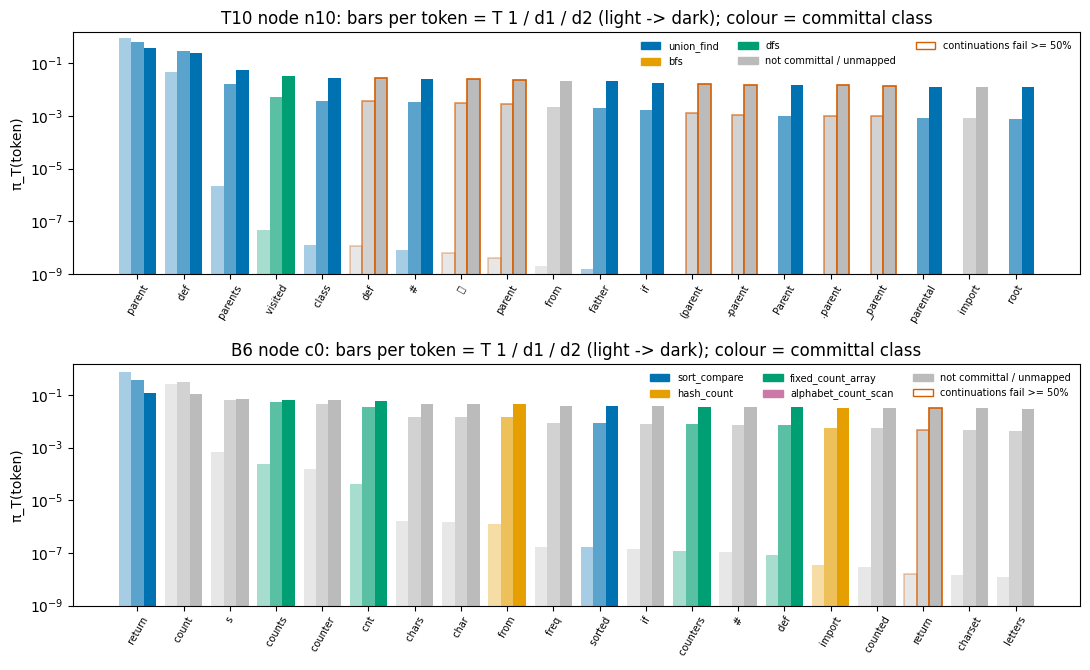

In [22]:
# [notebook] visual of the committed dose: pi_T(t | n) over the top-20 at T = 1, d1, d2
from matplotlib.patches import Patch
fig, axs = plt.subplots(len(UNITS_TO_RUN), 1, figsize=(11, 3.4 * len(UNITS_TO_RUN)), squeeze=False)
for ax, u in zip(axs[:, 0], UNITS_TO_RUN):
    e = tab["units"][u]
    nd = U8.nodes(u)[0]["id"]
    info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
    tf = info["tf"]["W1"]
    tm = e["token_map"][nd]
    cats = UNITS[u]["catalogue"]
    pal = dict(zip(cats, ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))
    ids = tf["top_ids"][:TOPK_DOSE]
    strs = [repr(tf["top_str"][i])[1:-1] if i < len(tf["top_str"]) else str(t) for i, t in enumerate(ids)]
    x = np.arange(len(ids))
    for j, (T, lab) in enumerate(((1.0, "T = 1"), (e["dose"]["d1"], f"d1 = {e['dose']['d1']:g}"),
                                  (e["dose"]["d2"], f"d2 = {e['dose']['d2']:g}"))):
        _, p = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], T, TOPK_DOSE)
        for xi, t, pp in zip(x, ids, p):
            m_ = tm.get(str(t), {})
            col = pal.get(m_.get("committal"), "#BBBBBB")
            ax.bar(xi + (j - 1) * 0.27, pp, width=0.27, color=col, alpha=[0.35, 0.65, 1.0][j],
                   edgecolor="#D55E00" if m_.get("pfail", 0) >= 0.5 else "none", linewidth=1.2)
    ax.set_yscale("log")
    ax.set_ylim(1e-9, 1.5)
    ax.set_xticks(x)
    ax.set_xticklabels(strs, rotation=60, fontsize=7)
    ax.set_ylabel("π_T(token)")
    ax.set_title(f"{u} node {nd}: bars per token = T 1 / d1 / d2 (light -> dark); colour = committal class")
    handles = [Patch(color=col, label=c_) for c_, col in pal.items()]
    handles += [Patch(color="#BBBBBB", label="not committal / unmapped"),
                Patch(facecolor="white", edgecolor="#D55E00", label="continuations fail >= 50%")]
    ax.legend(handles=handles, fontsize=7, ncol=3, frameon=False)
plt.tight_layout()
plt.show()

## `src/analysis_k1.py`: scoring the arms (code committed at COMMIT #1)

`load_rows` joins every program with its label: `cls` is the algorithm class (`invalid` if the program is
unparseable), and `passed` is the hidden-test result.
- Comparator families: global T (A1 / A2 / A3g), min-p (A4), EDT (A5), AdapT (A6).
- Placebos: entropy-max (A7), random window (A8).
- Fork doses: A9 / A10.

In [23]:
# ===== src/analysis_k1.py =====
"""Stage 6 (committed at COMMIT #1, before any Stage 3 sample): K1 cells, measures, verdicts; HR counts.

Cell measures (per unit x arm, 50 CRN slots): attempted / correct shares per class (invalid = not target), correct-only
Hill-1 rarefied to depth 25 (exact hypergeometric expectation of the Shannon entropy, exponentiated; NA if < 25
correct), pass rate, pass cost vs the twin (Newcombe hybrid-score 95% CI, exact McNemar on paired pass flips),
reversion, breakage, phrasing clusters per idea (identifier-normalised token 4-gram Jaccard components at 0.7/0.8/0.9),
reached-decision share, flips vs the twin. K1 (a)-(f), the disconfirming branches, the IUT primary p, the secondary
McNemar (A10 vs A3g on correct off-default flips) and the HR counts, all from data/*.jsonl and the committed table.
Usage: analysis_k1.py  -> results/k1_cells.json, results/k1_verdict.json, results/hr.json
"""

COMP_FAMILIES = {"global_T": ["A1", "A2", "A3g"], "min_p": ["A4"], "EDT": ["A5"], "AdapT": ["A6"]}
FORK = ["A9", "A10"]
PLACEBOS = {"entropy_max": ["A7"], "random_window": ["A8"]}
BAD = {"invalid", "no_code", "label_error", "extraction"}


def cls(unit: str, label: str | None, adjud: dict[str, str] | None = None, sid: str | None = None) -> str:
    if adjud and sid in adjud:
        return adjud[sid]
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_rows(adjud: dict[str, str] | None = None) -> dict[str, dict[str, dict[int, dict[str, Any]]]]:
    """unit -> arm -> slot -> row (with cls, passed)."""
    labels = {r["sid"]: r for r in read_jsonl(LABELS)}
    out: dict = defaultdict(lambda: defaultdict(dict))
    for r in read_jsonl(SAMPLES):
        if r.get("stage") not in ("S0", "S3") or r.get("slot") is None or r["arm"].endswith("_chk"):
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        r["label"] = L.get("label")
        r["cls"] = cls(r["unit"], L.get("label"), adjud, r["sid"])
        r["passed"] = bool(L.get("passed")) and r["cls"] != "invalid"
        r["code"] = L.get("code")
        out[r["unit"]][r["arm"]][int(r["slot"])] = r
    return out

### Ideas vs phrasings

This separates *ideas* (algorithm classes) from *phrasings* (surface variants of one algorithm). The correct
programs of each idea are clustered by identifier-normalised token 4-gram Jaccard similarity, at thresholds 0.7 /
0.8 / 0.9 (connected components). The research prompt asked whether sampling gives one idea in many phrasings or many
ideas; these clusters measure the phrasing side.

In [24]:
# ===== src/analysis_k1.py (continued) =====
# ------------------------------------------------------------------------------------------------ phrasing
def norm_tokens(code: str | None) -> list[str]:
    if not code:
        return []
    out = []
    try:
        for tk in tokenize.generate_tokens(io.StringIO(code).readline):
            if tk.type == tokenize.NAME:
                out.append(tk.string if keyword.iskeyword(tk.string) else "ID")
            elif tk.type == tokenize.NUMBER:
                out.append("NUM")
            elif tk.type == tokenize.STRING:
                out.append("STR")
            elif tk.type in (tokenize.OP,):
                out.append(tk.string)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        out = re.findall(r"\w+|[^\w\s]", code)
    return out


def phrasing_clusters(codes: list[str], thr: float) -> int:
    grams = []
    for c in codes:
        t = norm_tokens(c)
        grams.append({tuple(t[i:i + 4]) for i in range(max(len(t) - 3, 0))} or {tuple(t)})
    n = len(grams)
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for i in range(n):
        for j in range(i + 1, n):
            a, b = grams[i], grams[j]
            if len(a | b) and len(a & b) / len(a | b) >= thr:
                parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})

### Cell measures

For each unit × arm (50 paired slots), `cell_measures` computes:
- attempted and correct shares per class, and the pass rate;
- correct-only Hill-1, rarefied to 25 programs;
- pass cost vs the twin, with a Newcombe 95% CI and an exact McNemar test;
- how many slots changed their decision token, and the breakage among them;
- reversion: an off-default decision token whose program still ends in the default algorithm;
- label flips and phrasing clusters.

In [25]:
# ===== src/analysis_k1.py (continued) =====
# ------------------------------------------------------------------------------------------------ cell measures
def hill(rows: list[dict[str, Any]], depth: int = THRESH["hill_depth"]) -> float | None:
    return PR.hill1_rarefied([r["cls"] for r in rows if r["passed"]], depth)


def cell_measures(unit: str, arm_rows: dict[int, dict[str, Any]], twin: dict[int, dict[str, Any]],
                  tmap: dict[str, Any] | None, classes: list[str]) -> dict[str, Any]:
    slots = sorted(s for s in arm_rows if s in twin)
    rows = [arm_rows[s] for s in slots]
    n = len(rows)
    att = Counter(r["cls"] for r in rows)
    cor = Counter(r["cls"] for r in rows if r["passed"])
    default = UNITS[unit]["default"]
    p_arm = [arm_rows[s]["passed"] for s in slots]
    p_tw = [twin[s]["passed"] for s in slots]
    a = sum(1 for x, y in zip(p_tw, p_arm) if x and y)
    b = sum(1 for x, y in zip(p_tw, p_arm) if x and not y)
    c = sum(1 for x, y in zip(p_tw, p_arm) if not x and y)
    d = n - a - b - c
    nc = PR.newcombe_paired(a, b, c, d)
    # decision tokens: change, class, reversion, breakage
    tok_cls = {}
    for nd, m in (tmap or {}).items():
        for t, mm in m.items():
            tok_cls[(nd, int(t))] = mm.get("committal")
    changed, broke, offtok, reverted = 0, 0, 0, 0
    for s in slots:
        r, t = arm_rows[s], twin[s]
        if r.get("decision_token") is None or t.get("decision_token") is None:
            continue
        if r["decision_token"] != t["decision_token"]:
            changed += 1
            broke += int(not r["passed"])
        nd_ids = list((tmap or {}).keys())
        nd = nd_ids[r["decision_node"]] if 0 <= r.get("decision_node", -1) < len(nd_ids) else None
        cl = tok_cls.get((nd, int(r["decision_token"]))) if nd else None
        if cl is not None and cl != default and cl not in ("other", "invalid"):
            offtok += 1
            reverted += int(r["cls"] == default)
    flips = sum(1 for s in slots if arm_rows[s]["cls"] != twin[s]["cls"])
    ident = sum(1 for s in slots if arm_rows[s].get("token_ids") == twin[s].get("token_ids"))
    phr = {}
    for idea in sorted(cor):
        codes = [r.get("code") for r in rows if r["passed"] and r["cls"] == idea]
        phr[idea] = {str(th): phrasing_clusters(codes, th) for th in (0.7, 0.8, 0.9)}
    off_att = sum(v for k, v in att.items() if k not in (default, "other", "invalid")) / max(n, 1)
    off_cor = sum(v for k, v in cor.items() if k not in (default, "other", "invalid")) / max(n, 1)
    parseable = [r for r in rows if r["cls"] != "invalid"]
    off_att_parse = (sum(1 for r in parseable if r["cls"] not in (default, "other")) / len(parseable)) \
        if parseable else None
    return {"n": n, "attempted": {k: att.get(k, 0) / max(n, 1) for k in classes},
            "correct": {k: cor.get(k, 0) / max(n, 1) for k in classes}, "counts": dict(att),
            "correct_counts": dict(cor), "pass_rate": sum(p_arm) / max(n, 1), "hill1_correct_r25": hill(rows),
            "n_correct": sum(p_arm), "pass_cost": (sum(p_tw) - sum(p_arm)) / max(n, 1),
            "pass_cost_ci95": [nc["lo"], nc["hi"]], "mcnemar_pass": {"b_twin_only": b, "c_arm_only": c,
                                                                       "p": PR.mcnemar_exact(b, c)},
            "changed_decision": changed, "breakage": broke / changed if changed else None,
            "off_default_token": offtok, "reversion": reverted / offtok if offtok else None,
            "label_flips_vs_twin": flips, "byte_identical_to_twin": ident,
            "off_default_attempted": off_att, "off_default_correct": off_cor,
            "off_default_attempted_parseable": off_att_parse,
            "reached_decision": sum(1 for r in rows if r.get("reached_decision")) / max(n, 1),
            "phrasing_clusters": phr, "other_share": att.get("other", 0) / max(n, 1)}

### Paired slot bootstrap

The 50 slots are resampled `N_BOOT` times (seed 20261023). In each replicate, each family's best setting is the one
with the highest Hill-1 among those with pass cost ≤ 5 points. Because the selection happens inside the replicate,
the comparison is fair to the comparators. The statistic is the fork's best minus the family's best.

In [26]:
# ===== src/analysis_k1.py (continued) =====
# ------------------------------------------------------------------------------------------------ bootstrap
def boot_family_best(arms: dict[str, dict[int, dict[str, Any]]], twin: dict[int, dict[str, Any]], names: list[str],
                     idx: np.ndarray, slots: list[int]) -> float:
    """Best Hill among the family's settings whose pass cost <= 5 points on the resampled slots; twin Hill if none."""
    tw_rows = [twin[slots[i]] for i in idx]
    tw_pass = np.mean([r["passed"] for r in tw_rows])
    h_tw = PR.hill1_rarefied([r["cls"] for r in tw_rows if r["passed"]], THRESH["hill_depth"]) or 1.0
    best = None
    for a in names:
        if a not in arms:
            continue
        rr = [arms[a].get(slots[i]) for i in idx]
        if any(r is None for r in rr):
            continue
        cost = tw_pass - np.mean([r["passed"] for r in rr])
        if cost > THRESH["pass_cost_max"]:
            continue
        h = PR.hill1_rarefied([r["cls"] for r in rr if r["passed"]], THRESH["hill_depth"])
        if h is None:
            continue
        best = h if best is None else max(best, h)
    return best if best is not None else h_tw


def bootstrap_unit(unit: str, arms: dict[str, dict[int, dict[str, Any]]], n_boot: int = N_BOOT) -> dict[str, Any]:
    twin = arms["A0"]
    slots = sorted(s for s in twin if all(s in arms.get(a, {}) for a in FORK if a in arms))
    rng = np.random.default_rng(BOOT_SEED)
    fams = {**COMP_FAMILIES, **PLACEBOS}
    diffs = {f: [] for f in fams}
    diffs["best_comparator"] = []
    fork_best = []
    full = np.arange(len(slots))
    point = {"fork": boot_family_best(arms, twin, FORK, full, slots)}
    for f, names in fams.items():
        point[f] = boot_family_best(arms, twin, names, full, slots)
    for _ in range(n_boot):
        idx = rng.integers(0, len(slots), len(slots))
        fb = boot_family_best(arms, twin, FORK, idx, slots)
        fork_best.append(fb)
        cb = []
        for f, names in fams.items():
            v = boot_family_best(arms, twin, names, idx, slots)
            diffs[f].append(fb - v)
            if f in COMP_FAMILIES:
                cb.append(v)
        diffs["best_comparator"].append(fb - max(cb))
    out = {"point_best_hill": point, "n_slots": len(slots)}
    for f, v in diffs.items():
        v = np.array(v)
        out[f] = {"mean_diff": float(v.mean()), "lb_97_5": float(np.percentile(v, 2.5)),
                  "p_one_sided": float((np.sum(v <= 0) + 1) / (len(v) + 1))}
    return out

### The K1 verdicts

- **(a)** MAE of the composed and the replayed predictions vs the observed attempted shares.
- **(b) collapsed unit:** some fork arm reaches Hill-1 ≥ 1.8 at ≤ 5 points of pass cost, every comparator stays
  ≤ 1.15, and the bootstrap lower bound vs each family is positive.
- **(b) mixed units:** d1 lands within 0.10 of its target share, and Hill-1 reaches ≥ 1.8.
- **(c)** the twin's decision-token entropy is below q90.
- **(e)** reversion stays low.
- Also computed: the disconfirming branches, the IUT primary p, and the secondary exact McNemar test (A10 vs global
  T 2.0, on correct off-default flips).

In [27]:
# ===== src/analysis_k1.py (continued) =====
# ------------------------------------------------------------------------------------------------ verdicts
def mae(obs: dict[str, float], pred: dict[str, float], classes: list[str]) -> float:
    return float(np.mean([abs(obs.get(c, 0) - pred.get(c, 0)) for c in classes]))


def run(adjud: dict[str, str] | None = None, n_boot: int = N_BOOT) -> dict[str, Any]:
    c1 = read_json(PRED_DIR / "commit1_dose_table.json")
    data = load_rows(adjud)
    cells: dict = {}
    verdict: dict = {"utc": utc_now(), "units": {}}
    for unit, arms in data.items():
        if "A0" not in arms:
            continue
        e = c1["units"].get(unit, {})
        classes = e.get("classes") or (list(UNITS[unit]["catalogue"]) + ["other", "invalid"])
        tmap = e.get("token_map")
        cells[unit] = {a: cell_measures(unit, rows, arms["A0"], tmap, classes) for a, rows in arms.items()}
    verdict["cells"] = cells
    # (a) MAE per located unit, replay MAE
    a_res = {}
    for unit, e in c1["units"].items():
        if e.get("role") == "boundary" or unit not in cells:
            continue
        errs, rerrs = [], []
        for arm in ("A9", "A10"):
            if arm not in cells[unit]:
                continue
            obs = cells[unit][arm]["attempted"]
            errs.append(mae(obs, e["arms"][arm]["attempted"], e["classes"]))
            rerrs.append(mae(obs, e["arms"][arm]["replay"]["attempted"], e["classes"]))
        if errs:
            a_res[unit] = {"mae": float(np.mean(errs)), "mae_replay": float(np.mean(rerrs)),
                           "pass": float(np.mean(errs)) <= THRESH["mae_max"],
                           "noise_ceiling": c1["mae_noise_ceiling"]["per_unit"].get(unit)}
    frac = np.mean([v["pass"] for v in a_res.values()]) if a_res else 0.0
    verdict["K1a"] = {"per_unit": a_res, "frac_units_pass": float(frac), "pass": bool(frac >= THRESH["mae_units_frac"]),
                      "noise_ceiling_all": c1["mae_noise_ceiling"]["P_mae_le_0.10_if_true"]}
    # (b) collapsed: Hill bootstrap; mixed: d1 target + Hill >= 1.8 on >= 4 units
    b_res, iut_ps, mixed_hill_ok = {}, [], []
    for unit, e in c1["units"].items():
        if unit not in data or e.get("role") == "boundary":
            continue
        arms = data[unit]
        if not all(a in arms for a in FORK):
            continue
        bs = bootstrap_unit(unit, arms, n_boot)
        fork_cells = {a: cells[unit][a] for a in FORK}
        ok_fork = [a for a in FORK if (fork_cells[a]["hill1_correct_r25"] or 0) >= THRESH["hill_min"]
                   and fork_cells[a]["pass_cost"] <= THRESH["pass_cost_max"]]
        comp_max = {f: max([(cells[unit][a]["hill1_correct_r25"] or 0) for a in names if a in cells[unit]] or [0])
                    for f, names in COMP_FAMILIES.items()}
        res = {"bootstrap": bs, "fork_arms_meeting_hill_and_cost": ok_fork, "comparator_point_max_hill": comp_max}
        if e["role"] == "collapsed":
            res["pass"] = bool(ok_fork) and all(v <= THRESH["hill_comp_max"] for v in comp_max.values()) and \
                all(bs[f]["lb_97_5"] > 0 for f in COMP_FAMILIES)
            iut_ps.append(bs["best_comparator"]["p_one_sided"])
        else:
            tgt = e["dose"].get("target_share_d1")
            share_d1 = cells[unit]["A9"]["off_default_attempted"]
            res["d1_target"] = tgt
            res["d1_observed_minority"] = share_d1
            res["d1_within_0.10"] = (abs(share_d1 - tgt) <= THRESH["d1_target_tol"]) if tgt is not None else None
            hb = max((fork_cells[a]["hill1_correct_r25"] or 0) for a in FORK)
            res["best_fork_hill"] = hb
            mixed_hill_ok.append(hb >= THRESH["hill_min"])
        b_res[unit] = res
    verdict["K1b"] = {"per_unit": b_res, "mixed_units_hill_ok": int(sum(mixed_hill_ok)),
                      "collapsed_pass": [u for u, r in b_res.items() if r.get("pass")]}
    verdict["primary_p_IUT"] = max(iut_ps) if iut_ps else None
    # (c) twin decision-token entropy vs q90
    verdict["K1c"] = {u: e.get("entropy_check_c") for u, e in c1["units"].items() if e.get("role") != "boundary"}
    for u in list(verdict["K1c"]):
        if u in cells and "A7" in cells[u]:
            twin = data[u]["A0"]
            jst = c1["units"][u]["jstar"]
            hits = sum(1 for s, r in twin.items() if r.get("reached_decision") and
                       int(jst.get(str(s), -9)) == r["decision_pos"])
            verdict["K1c"][u] = {**(verdict["K1c"][u] or {}), "A7_hits_decision": hits}
    # (d) boundary window
    d_res = {}
    for unit in cells:
        if "B1" not in cells[unit]:
            continue
        tw, bw = cells[unit]["A0"], cells[unit]["B1"]
        dc = bw["off_default_correct"] - tw["off_default_correct"]
        da = (bw["off_default_attempted_parseable"] or 0) - (tw["off_default_attempted_parseable"] or 0)
        d_res[unit] = {"d_off_correct": dc, "d_off_attempted_parseable": da, "window_pass_rate": bw["pass_rate"],
                       "untestable_by_breakage": bw["pass_rate"] < THRESH["boundary_pass_min"],
                       "pass": abs(dc) <= THRESH["boundary_move_max"] and abs(da) <= THRESH["boundary_move_max"]}
    verdict["K1d"] = d_res
    # (e) reversion pooled
    num = den = 0
    for unit in cells:
        for a in FORK:
            cm = cells[unit].get(a)
            if cm and cm["off_default_token"]:
                den += cm["off_default_token"]
                num += round((cm["reversion"] or 0) * cm["off_default_token"])
    verdict["K1e"] = {"pooled_reversion": num / den if den else None, "n_off_tokens": den,
                      "pass": (num / den <= THRESH["reversion_max"]) if den else None}
    # (f) Gemma
    if "G" in cells and "A10" in cells["G"]:
        e = c1["units"]["G"]
        pred_cost = e["arms"]["A10"]["pass_cost"]
        obs_cost = cells["G"]["A10"]["pass_cost"]
        a11 = data["G"].get("A11", {})
        queue = sum(1 for r in a11.values() if r.get("decision_token") == 15204)
        verdict["K1f"] = {"pred_pass_cost": pred_cost, "obs_pass_cost": obs_cost,
                          "pred_fail_d2_sum_pi_Pfail": e.get("sum_pi_Pfail_d2"), "queue_term": e.get("queue_term"),
                          "obs_fail_A10": 1 - cells["G"]["A10"]["pass_rate"],
                          "within_0.10": abs(pred_cost - obs_cost) <= THRESH["g_pass_cost_tol"],
                          "A11_queue_slots": queue,
                          "A11_cost_le_A10": (cells["G"]["A11"]["pass_cost"] <= obs_cost) if "A11" in cells["G"]
                          else None}
    # disconfirming
    disc = {"share": [], "cost": [], "reversion": verdict["K1e"]["pooled_reversion"]}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in cells:
            continue
        for a in FORK:
            if a in cells[unit]:
                disc["share"].append(cells[unit][a]["off_default_correct"] - cells[unit]["A0"]["off_default_correct"])
                disc["cost"].append(cells[unit][a]["pass_cost"])
    verdict["disconfirming"] = {
        "share_below_0.10_everywhere": bool(disc["share"]) and all(x < THRESH["disconfirm_share"] for x in disc["share"]),
        "cost_above_0.10": any(x > THRESH["disconfirm_cost"] for x in disc["cost"]),
        "reversion_above_0.30": (disc["reversion"] or 0) > THRESH["disconfirm_reversion"], "values": disc}
    # secondary: exact McNemar on correct off-default flips, A10 vs A3g (collapsed units)
    sec = {}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in data:
            continue
        A, G = data[unit].get("A10", {}), data[unit].get("A3g", {})
        default = UNITS[unit]["default"]

        def cod(r):
            return bool(r["passed"]) and r["cls"] not in (default, "other", "invalid")
        sl = [s for s in A if s in G]
        b = sum(1 for s in sl if cod(A[s]) and not cod(G[s]))
        c = sum(1 for s in sl if cod(G[s]) and not cod(A[s]))
        sec[unit] = {"b_A10_only": b, "c_A3g_only": c, "p_one_sided": PR.mcnemar_exact(b, c, "greater")}
    verdict["secondary_mcnemar_A10_vs_A3g"] = sec
    return verdict


AK = as_module("analysis_k1", ["COMP_FAMILIES", "FORK", "PLACEBOS", "BAD", "cls", "load_rows", "norm_tokens",
                               "phrasing_clusters", "hill", "cell_measures", "boot_family_best", "bootstrap_unit",
                               "mae", "run"])

## Run the K1 analysis

This is the `__main__` block of `analysis_k1.py`: score every cell, run the bootstrap, and write
`results/k1_cells.json` and `results/k1_verdict.json`. The bootstrap is the slow part (a few seconds per unit at
`N_BOOT = 2000`).

The pooled numbers cover only the units run here. For example, K1(e) reversion is pooled over T10 and B6 (0 of 15
off-default decision tokens reverted), where the full run pooled 5 units (4 of 102).

In [28]:
# ===== src/analysis_k1.py __main__ =====
adj_p = RESULTS_DIR / "adjudicated_labels.json"
adj = read_json(adj_p) if adj_p.exists() else None
t0 = time.time()
v = AK.run(adj)
write_json(RESULTS_DIR / "k1_cells.json", v["cells"])
write_json(RESULTS_DIR / "k1_verdict.json", {k: x for k, x in v.items() if k != "cells"})
print(json.dumps({k: x for k, x in v.items() if k not in ("cells", "K1b")}, indent=1, default=str)[:3000])
print(f"[notebook] K1 analysis took {time.time() - t0:.1f}s")

{
 "utc": "2026-10-26T14:03:35.873937Z",
 "units": {},
 "K1a": {
  "per_unit": {
   "T10": {
    "mae": 0.017030000000000003,
    "mae_replay": 0.013481999999999989,
    "pass": true,
    "noise_ceiling": 1.0
   },
   "B6": {
    "mae": 0.04748083333333333,
    "mae_replay": 0.03133333333333334,
    "pass": true,
    "noise_ceiling": 1.0
   }
  },
  "frac_units_pass": 1.0,
  "pass": true,
  "noise_ceiling_all": 1.0
 },
 "primary_p_IUT": 0.3008495752123938,
 "K1c": {
  "T10": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 50,
   "A7_hits_decision": 2
  },
  "B6": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 39,
   "A7_hits_decision": 21
  }
 },
 "K1d": {},
 "K1e": {
  "pooled_reversion": 0.0,
  "n_off_tokens": 15,
  "pass": true
 },
 "disconfirming": {
  "share_below_0.10_everywhere": false,
  "cost_above_0.10": true,
  "reversion_above_0.30": false,
  "values": {
   "share": [
    0.06,
    0.16
   ],
   "cost": [
    0.02,
    0.14
   ],
   "reversion": 0.0
  }
 },
 "secondary_mcnem

### Every arm, per unit (notebook addition)

These are the README's tables, recomputed. **Shares** are the attempted algorithm shares over the 50 slots, and
**correct Hill-1** is the number of effectively distinct correct ideas. **Phrasings @0.8** counts the phrasing
clusters within the most common correct idea. What to look for:
- on **T10**, global temperature never leaves union-find (DFS 0-2/50), while the fork dose reaches DFS 3/50 (d1) and
  9/50 (d2), at a pass cost at d2;
- on **B6**, the fork dose moves correct diversity from Hill-1 1.78 to 2.78 at almost no cost.

In [29]:
# [notebook] readable per-arm tables from the K1 cells just computed
ARM_DESC = {"A0": "twin T=1", "A1": "global T1.3 top-p.95", "A2": "global T1.6 top-p.95", "A3g": "global T2.0 top-p.95",
            "A4": "min-p 0.1 at T3", "A5": "EDT-style", "A6": "AdapT-style", "A7": "dose at entropy-max pos.",
            "A8": "dose at random pos.", "A9": "FORK dose d1", "A10": "FORK dose d2", "A11": "class-uniform forcing",
            "A9f": "filtered fork d1 (amend.)", "A10f": "filtered fork d2 (amend.)"}
ORDER_ARMS = list(ARM_DESC)
for u in UNITS_TO_RUN:
    cl = [c for c in UNITS[u]["catalogue"] + ["other", "invalid"]
          if any(v["cells"][u][a]["counts"].get(c) for a in v["cells"][u])]
    rows_ = []
    for a in sorted(v["cells"][u], key=ORDER_ARMS.index):
        c = v["cells"][u][a]
        T = tab["units"][u]["arms"].get(a, {}).get("T") if a in ("A9", "A10") else None
        top_idea = max(c["correct_counts"], key=c["correct_counts"].get) if c["correct_counts"] else None
        rows_.append({"arm": a, "what": ARM_DESC[a] + (f" (T={T:g})" if T else ""),
                      **{c_: c["counts"].get(c_, 0) for c_ in cl},
                      "pass": round(c["pass_rate"], 2),
                      "correct Hill-1": None if c["hill1_correct_r25"] is None else round(c["hill1_correct_r25"], 2),
                      "pass cost [95% CI]": f'{c["pass_cost"]:+.2f} [{c["pass_cost_ci95"][0]:+.2f}, {c["pass_cost_ci95"][1]:+.2f}]',
                      "decision changed": c["changed_decision"],
                      "phrasings@0.8 (top idea)": c["phrasing_clusters"].get(top_idea, {}).get("0.8") if top_idea else None})
    print(f"\n{u} ({UNITS[u]['task']}, role {tab['units'][u]['role']}): program counts per algorithm, N = 50 slots per arm")
    display(pd.DataFrame(rows_).set_index("arm"))


T10 (connected components, role collapsed): program counts per algorithm, N = 50 slots per arm


,what,union_find,bfs,dfs,invalid,pass,correct Hill-1,pass cost [95% CI],decision changed,phrasings@0.8 (top idea)
arm,,,,,,,,,,
A0,twin T=1,50,0,0,0,1.00,1.00,"+0.00 [-0.07, +0.07]",0,3
A1,global T1.3 top-p.95,50,0,0,0,1.00,1.00,"+0.00 [-0.07, +0.07]",3,3
A2,global T1.6 top-p.95,50,0,0,0,1.00,1.00,"+0.00 [-0.07, +0.07]",5,4
A3g,global T2.0 top-p.95,47,0,2,1,0.98,1.17,"+0.02 [-0.05, +0.10]",11,3
A4,min-p 0.1 at T3,49,0,1,0,1.00,1.09,"+0.00 [-0.07, +0.07]",2,3
A5,EDT-style,47,0,2,1,0.98,1.17,"+0.02 [-0.05, +0.10]",11,3
A6,AdapT-style,50,0,0,0,1.00,1.00,"+0.00 [-0.07, +0.07]",11,3
A7,dose at entropy-max pos.,50,0,0,0,0.96,1.00,"+0.04 [-0.04, +0.13]",1,3
A8,dose at random pos.,43,0,0,7,0.80,1.00,"+0.20 [+0.09, +0.33]",1,4



B6 (valid anagram, role mixed): program counts per algorithm, N = 50 slots per arm


,what,sort_compare,hash_count,fixed_count_array,alphabet_count_scan,invalid,pass,correct Hill-1,pass cost [95% CI],decision changed,phrasings@0.8 (top idea)
arm,,,,,,,,,,,
A0,twin T=1,40,2,8,0,0,1.00,1.78,"+0.00 [-0.07, +0.07]",0,2
A1,global T1.3 top-p.95,40,3,7,0,0,1.00,1.82,"+0.00 [-0.07, +0.07]",2,2
A2,global T1.6 top-p.95,39,2,9,0,0,1.00,1.83,"+0.00 [-0.07, +0.07]",1,2
A3g,global T2.0 top-p.95,38,2,10,0,0,1.00,1.89,"+0.00 [-0.07, +0.07]",2,2
A5,EDT-style,38,2,10,0,0,1.00,1.89,"+0.00 [-0.07, +0.07]",2,2
A7,dose at entropy-max pos.,19,11,17,0,3,0.94,2.87,"+0.06 [-0.02, +0.16]",18,3
A8,dose at random pos.,35,3,9,0,3,0.92,1.95,"+0.08 [-0.01, +0.19]",2,2
A9,FORK dose d1 (T=4),30,3,17,0,0,1.00,2.27,"+0.00 [-0.07, +0.07]",16,2
A10,FORK dose d2 (T=13),21,9,19,0,1,0.98,2.78,"+0.02 [-0.05, +0.10]",32,3


### One CRN slot, two arms (notebook addition)

Here is the same prompt and the same random numbers under the twin and under the fork dose d2, at a slot where the
dose changed the algorithm. The code is the program the labeller extracted.

In [30]:
# [notebook] show one slot where the fork dose flipped the algorithm (code is stored for passing programs)
for u in UNITS_TO_RUN:
    rows_u = AK.load_rows(adj)[u]
    default = UNITS[u]["default"]
    flip = next((s for s in sorted(rows_u["A10"]) if rows_u["A0"][s]["cls"] == default and rows_u["A0"][s]["passed"]
                 and rows_u["A10"][s]["cls"] not in (default, "invalid", "other") and rows_u["A10"][s]["passed"]), None)
    if flip is None:
        continue
    for a in ("A0", "A10"):
        r_ = rows_u[a][flip]
        print(f"--- {u} slot {flip} ({r_['w']}), arm {a}: decision token {r_.get('decision_token_str')!r} at index "
              f"{r_.get('decision_pos')} -> {r_['cls']}, passed={r_['passed']}")
        print("\n".join((r_.get("code") or "").splitlines()[:22]))

--- T10 slot 0 (W1), arm A0: decision token ' parent' at index 10 -> union_find, passed=True
def solve(n, edges):
    parent = list(range(n))
    
    def find(x):
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]
    
    def union(x, y):
        rootX = find(x)
        rootY = find(y)
        if rootX != rootY:
            parent[rootY] = rootX
    
    for u, v in edges:
        union(u, v)
    
    roots = set()
    for i in range(n):
        roots.add(find(i))
    
    return len(roots)
--- T10 slot 0 (W1), arm A10: decision token ' def' at index 10 -> dfs, passed=True
def solve(n, edges):
    def connected_components():
        visited = [False] * n
        count = 0
        for i in range(n):
            if not visited[i]:
                count += 1
                stack = [i]
                visited[i] = True
                while stack:
                    node = stack.pop()
                    for neighbor in graph[node]:
            

## The amendment, COMMIT #3: the same dose without the candidates that break programs (`src/amend8.py`)

The token map already shows which candidates break programs: at T10's decision, `_parent`, `-parent`, `父` and others
fail 10/10. After the primary T10 / B3 / G cells were seen, one amendment was committed before any of its own
samples. It applies the same fork dose but removes from the top-20 every token whose committed continuations fail
≥ 50% of the time, then re-applies the committed dose rules to the filtered composition.

On T10 this removes 8 index-10 tokens and 4 index-11 tokens. (Gemma's G unit is not in the demo data.)

In [31]:
# ===== src/amend8.py =====
"""AMENDMENT (COMMIT #3, after the primary Stage 3 results of T10/B3/G were seen, before any of its own samples):
the pass-filtered fork dose. Same knob as A9/A10 (T = d, top-20, at the decision index only; T10 also at index 11
after ' def'), but the tokens whose Stage 2 continuations fail >= 50% of the time (Pfail >= 0.5 in the COMMITTED
token map) are removed from the top-20 at the dosed step. Units: T10 (format-breaking index-10 tokens) and G (the
` queue` token). Doses by the committed rules applied to the filtered composition. It never replaces A9/A10.
Usage: amend8.py  -> predictions/commit3_amendment.json + COMMIT3_amendment
"""

PFAIL_BAN = 0.5


def main() -> None:
    # [notebook] the original asserted that no amendment sample exists yet; the demo data already holds them:
    # assert not any(r.get("arm") in ("A9f", "A10f") for r in read_jsonl(SAMPLES)), "amendment samples exist"
    labels = D.load_labels()
    out = {"utc": utc_now(), "rule": f"ban tokens with committed Pfail >= {PFAIL_BAN} at each dosed node",
           "units": {}}
    for unit in [u for u in ("T10", "G") if u in UNITS_TO_RUN]:   # [notebook] G is not in the demo data
        M = D.UnitModel(unit, labels)
        bans = {}
        for nd in M.nodes:
            bans[f"{unit}:{nd['id']}"] = {int(t) for t, m in nd["tmap"].items() if m["pfail"] >= PFAIL_BAN}
        if unit == "T10" and M.second:
            bans["T10:n11"] = {int(t) for t, m in M.second["tmap"].items() if m["pfail"] >= PFAIL_BAN}
        D.BAN.clear()
        D.BAN.update(bans)
        role = "collapsed" if unit == "T10" else "mixed"
        dt = D.dose_table(M, role)
        base = M.predict(1.0)
        arms = {}
        for name, T in (("A9f", dt["d1"]), ("A10f", dt["d2"])):
            pr = M.predict(T)
            rp = M.replay_cell(T)
            arms[name] = {"T": T, "attempted": dict(zip(M.C, np.round(pr["P"], 5).tolist())),
                          "correct": dict(zip(M.C, np.round(pr["Pc"], 5).tolist())),
                          "pass_cost": float(pr["fail"] - base["fail"]),
                          "off_default_attempted": M.off_default_share(pr["P"]),
                          "replay": {"attempted": dict(zip(M.C, np.round(rp["P"], 5).tolist())),
                                     "n_changed": rp["n_changed"]}}
        out["units"][unit] = {"bans": {k: sorted(v) for k, v in bans.items()},
                              "ban_str": {k: [M.nodes[0]["info"]["map_token_str"].get(str(t), "?") if not
                                              k.endswith("n11") else
                                              (M.second["info"]["map_token_str"].get(str(t), "?")) for t in sorted(v)]
                                          for k, v in bans.items()},
                              "dose": {k: dt[k] for k in ("d1", "d2", "rule", "max_share", "target_share_d1",
                                                          "T_at_max")},
                              "share_curve": dt["share_curve"], "classes": M.C, "arms": arms}
        D.BAN.clear()
    write_json(PRED_DIR / "commit3_amendment.json", out)
    # [notebook] the original also committed src/amend8.py, dose8.py, engine8.py, arms8.py
    e = CM.commit("COMMIT3_amendment", [PRED_DIR / "commit3_amendment.json"])
    print("COMMIT #3", e["utc"])
    for u, x in out["units"].items():
        print(u, x["dose"], {a: (round(v["off_default_attempted"], 3), round(v["pass_cost"], 3)) for a, v in
                             x["arms"].items()}, x["ban_str"])


main()

COMMIT #3 2026-10-26T14:03:41.867390Z
T10 {'d1': 5.0, 'd2': 10.0, 'rule': 'attainable max 0.188 < 0.40: d2 = 0.95 x max, d1 = half of max', 'max_share': 0.18818375035060825, 'target_share_d1': 0.09409187517530412, 'T_at_max': 23.0} {'A9f': (0.124, 0.018), 'A10f': (0.179, 0.035)} {'T10:n10': ['def', 'parent', ' visit', '.parent', '(parent', '_parent', '-parent', '父'], 'T10:n11': ['find', 'dfs', 'DFS', ' bfs']}


### Scoring the amendment (`src/amend_analysis8.py`)

This compares observed vs committed shares, pass cost and correct Hill-1 for the filtered arms A9f / A10f, and runs
the same paired slot bootstrap: the best filtered setting vs each comparator family.

In [32]:
# ===== src/amend_analysis8.py =====
"""Analysis of the COMMIT #3 amendment (pass-filtered fork dose A9f/A10f on T10 and G): observed vs committed shares
(MAE, replay MAE), pass cost, correct Hill-1, and the same paired slot bootstrap as K1(b) (best filtered setting under
the 5-point cost constraint vs each comparator family, selection inside each replicate). Secondary, post-amendment.
Writes results/amendment.json."""

FILT = ["A9f", "A10f"]


def main() -> None:
    c3 = read_json(PRED_DIR / "commit3_amendment.json")
    adj_p = RESULTS_DIR / "adjudicated_labels.json"
    data = AK.load_rows(read_json(adj_p) if adj_p.exists() else None)
    out = {"utc": utc_now(), "units": {}}
    for unit, e in c3["units"].items():
        arms = data.get(unit, {})
        if not all(a in arms for a in FILT):
            continue
        tw = arms["A0"]
        cells = {a: AK.cell_measures(unit, arms[a], tw, None, e["classes"]) for a in FILT}
        mae = {a: AK.mae(cells[a]["attempted"], e["arms"][a]["attempted"], e["classes"]) for a in FILT}
        rmae = {a: AK.mae(cells[a]["attempted"], e["arms"][a]["replay"]["attempted"], e["classes"]) for a in FILT}
        slots = sorted(s for s in tw if all(s in arms[a] for a in FILT))
        rng = np.random.default_rng(BOOT_SEED)
        fams = {**AK.COMP_FAMILIES, **AK.PLACEBOS, "fork_primary": AK.FORK}
        diffs = {f: [] for f in fams}
        full = np.arange(len(slots))
        point = {"filtered": AK.boot_family_best(arms, tw, FILT, full, slots)}
        point.update({f: AK.boot_family_best(arms, tw, n, full, slots) for f, n in fams.items()})
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(slots), len(slots))
            fb = AK.boot_family_best(arms, tw, FILT, idx, slots)
            for f, n in fams.items():
                diffs[f].append(fb - AK.boot_family_best(arms, tw, n, idx, slots))
        out["units"][unit] = {
            "dose": e["dose"], "cells": {a: {k: cells[a][k] for k in ("attempted", "correct", "pass_rate", "pass_cost",
                                                                     "pass_cost_ci95", "hill1_correct_r25",
                                                                     "changed_decision", "breakage")} for a in FILT},
            "pred": {a: {k: e["arms"][a][k] for k in ("attempted", "pass_cost", "off_default_attempted")} for a in FILT},
            "mae": mae, "mae_replay": rmae, "point_best_hill": point,
            "bootstrap_vs": {f: {"mean_diff": float(np.mean(v)), "lb_97_5": float(np.percentile(v, 2.5)),
                                 "p_one_sided": float((np.sum(np.array(v) <= 0) + 1) / (len(v) + 1))}
                             for f, v in diffs.items()}}
    write_json(RESULTS_DIR / "amendment.json", out)
    for u, x in out["units"].items():
        print(u, {a: (round(x["cells"][a]["pass_cost"], 3), x["cells"][a]["hill1_correct_r25"]) for a in FILT},
              "mae", x["mae"], "best", x["point_best_hill"])


main()

T10 {'A9f': (0.02, 1.544177016011695), 'A10f': (0.02, 1.374728140597634)} mae {'A9f': 0.023296000000000004, 'A10f': 0.024058000000000006} best {'filtered': 1.544177016011695, 'global_T': 1.1697621356943992, 'min_p': 1.0875985209638772, 'EDT': 1.1697621356943992, 'AdapT': 1.0, 'entropy_max': 1.0, 'random_window': 1.0, 'fork_primary': 1.2431450042992862}


## HR: the hidden repertoire behind the decision token (`src/hr8.py`)

**Can forcing reach ideas that no sampling knob reaches?** At every decision node, each of the 64 most probable
tokens was forced and continued 5 times at T = 1 (Stage 4). An idea counts as reached when at least one forced
continuation is a correct program of it. For each idea reached only by HR, the module computes its T = 1
reachability mass, m = Σ_c w_c Σ_t π_1(t | n_c) f(idea | n_c, t), and the expected number of T = 1 samples (1 / m)
before it appears once.

`arms8.hr_tokens` ranks the candidates. `forced_ideas` read two older artifacts' forced-program results; their
values ship in the demo data.

In [33]:
# ===== src/arms8.py: hr_tokens only (the rest of arms8 builds the GPU stage-3/4 specs) =====
def hr_tokens(info: dict[str, Any]) -> list[tuple[int, int]]:
    """(rank, token) for ranks 1-64 by the template-averaged T = 1 probability over the saved top-64 logits."""
    pooled: dict[int, float] = {}
    for w in TEMPLATES:
        ids = info["tf"][w]["top_ids"]
        z = np.array(info["tf"][w]["top_z"], dtype=float)
        p = np.exp(z - z.max())
        p /= p.sum()          # normalised over the top-64 (the mass outside is < 1e-3 at every node)
        for t, pp in zip(ids, p):
            pooled[int(t)] = pooled.get(int(t), 0.0) + pp / len(TEMPLATES)
    order = sorted(pooled, key=lambda t: -pooled[t])[:HR_RANKS]
    return [(i + 1, t) for i, t in enumerate(order)]


arms8 = as_module("arms8", ["hr_tokens"])

### `src/hr8.py`: ideas reached by forcing vs ideas reached by sampling

`run` collects, per node, the HR continuations plus the first 5 token-map continuations, which are the HR samples of
ranks 1-24. It then compares three sets of correct ideas:
- `ideas_HR`: reached by forcing any of the top-64 candidates;
- `ideas_Kstar`: reached by any sampling arm, A0-A10;
- `ideas_global_T`: reached by global temperature alone.

For every idea it also computes T = 1 reachability, and the largest mass any fork dose gives it.

In [34]:
# ===== src/hr8.py =====
"""Stage 4 analysis (HR, hidden repertoire): ideas reachable by forcing any of the top-64 tokens at each decision node
(5 T = 1 continuations each; ranks within the Stage 2 map reuse its first 5 continuations) vs ideas reached by the
sampling knobs (A0-A10; A11 is forcing), the global-T arms alone, the forced can-rates and iteration-7 search clusters.
An IDEA is a catalogue label, or for correct 'other' programs the novelty audit's adjudicated name.
Per HR-only idea: T = 1 reachability mass m = sum_c w_c sum_t pi_1(t | n_c) f(idea | n_c, t) over the saved top-64,
the expected number of T = 1 samples to see it once (1 / m), and the smallest fork dose (top-20) with m_T >= 0.05.
Writes results/hr.json.
"""

SAMPLING_ARMS = ["A0", "A1", "A2", "A3g", "A4", "A5", "A6", "A7", "A8", "A9", "A10"]
GLOBAL_T = ["A0", "A1", "A2", "A3g"]
NODES = {"T10": ["n10", "n11"], "B3": ["c0", "c1"], "A3": ["c0", "c1"], "B6": ["c0"], "G": ["cstar"], "T1": ["n3"]}


def idea_of(unit: str, label: str | None, sid: str, adjud: dict[str, str]) -> str:
    if sid in adjud:
        return adjud[sid]
    return AK.cls(unit, label)


def forced_ideas(unit: str) -> set[str]:
    # [notebook] the original body (commented out below) reads exp35 results/s4b.json and the iteration-2
    # T10_forced_programs.jsonl, which are not in the demo data; the sets it returned are stored there
    return set(data["unit_resources"]["forced_ideas"].get(unit, []))
    # out: set[str] = set()
    # if unit in ("B3", "A3", "B6"):
    #     s4b = read_json(E35 / "results" / "s4b.json")
    #     u = s4b.get(unit) or s4b.get("units", {}).get(unit) or {}
    #     u = u.get("arms", u) if isinstance(u, dict) else {}
    #     for arm in ("FORCED", "EXCH"):
    #         d = u.get(arm) if isinstance(u, dict) else None
    #         if isinstance(d, dict):
    #             for k in ("labels", "counts", "label_counts"):
    #                 if isinstance(d.get(k), dict):
    #                     out |= {x for x in d[k] if x in UNITS[unit]["catalogue"]}
    # if unit == "T10":
    #     for r in read_jsonl(INPUTS / "iter2_exp11" / "bench" / "T10_forced_programs.jsonl"):
    #         lab = r.get("label") or r.get("mode") or r.get("algorithm")
    #         if lab in UNITS[unit]["catalogue"]:
    #             out.add(lab)
    # return out


def run(adjud: dict[str, str] | None = None) -> dict:
    adjud = adjud or {}
    labels = {r["sid"]: r for r in read_jsonl(CONT_LABELS)}
    cont = defaultdict(list)          # (unit, node) -> rows
    for r in read_jsonl(CONTS):
        if r.get("arm") == "MAP" and r.get("k", 99) < K_HR or r.get("arm") == "HR":
            L = labels.get(r["sid"])
            if L is None:
                continue
            r["idea"] = idea_of(r["unit"], L.get("label"), r["sid"], adjud)
            r["passed"] = bool(L.get("passed")) and r["idea"] != "invalid"
            cont[(r["unit"], r["node"])].append(r)
    data = AK.load_rows(adjud)
    out = {"utc": utc_now(), "units": {}}
    n_units_extra = 0
    for unit, nodes in NODES.items():
        rows = [r for n in nodes for r in cont.get((unit, n), [])]
        if not rows:
            continue
        has_hr = any(r["arm"] == "HR" for r in rows)
        ideas_hr = {r["idea"] for r in rows if r["passed"]}
        arms = data.get(unit, {})
        ideas_k = {a: sorted({idea_of(unit, r["label"], r["sid"], adjud) for r in arms[a].values() if r["passed"]}
                             - {"invalid"}) for a in SAMPLING_ARMS if a in arms}
        kstar = set().union(*[set(v) for v in ideas_k.values()]) if ideas_k else set()
        kglob = set().union(*[set(ideas_k[a]) for a in GLOBAL_T if a in ideas_k]) if ideas_k else set()
        hr_only = sorted(ideas_hr - kstar - {"invalid"})
        # reachability of every idea (T = 1 over the saved top-64, and fork doses over the top-20)
        reach = {}
        for idea in sorted(ideas_hr | kstar):
            m1, mT = 0.0, {}
            for n in nodes:
                p = CACHE_DIR / "nodes" / f"{unit}_{n}.json"
                if not p.exists():
                    continue
                info = read_json(p)
                f = defaultdict(list)
                for r in cont.get((unit, n), []):
                    f[int(r["token"])].append(r["idea"] == idea and r["passed"])
                freq = {t: float(np.mean(v)) for t, v in f.items()}
                if unit == "T10" and n == "n10" and "n11" in nodes:
                    freq.pop(U8.T10_DEF, None)          # ' def' is followed through n11 (no double count)
                parent = None
                if n == "n11":                      # reached through ' def' at n10: weight by its probability there
                    parent = read_json(CACHE_DIR / "nodes" / f"{unit}_n10.json")

                def via(w: str, T: float, k: int) -> float:
                    if parent is None:
                        return 1.0
                    tfp = parent["tf"][w]
                    ids_p, pr_p = PR.dist_top_from_saved(tfp["top_ids"], tfp["top_z"], T, k)
                    d = dict(zip(ids_p.tolist(), pr_p.tolist()))
                    return math.exp(tfp["path_logprob"]) * d.get(U8.T10_DEF, 0.0)
                wsum = []
                for w in TEMPLATES:
                    tf = info["tf"][w]
                    ids, pr = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], 1.0, 64)
                    wc = math.exp(tf["path_logprob"]) if parent is None else via(w, 1.0, 64)
                    wsum.append(wc * sum(pp * freq.get(int(t), 0.0) for t, pp in zip(ids, pr)))
                m1 += float(np.mean(wsum))
                for T in DOSE_GRID:
                    v = []
                    for w in TEMPLATES:
                        tf = info["tf"][w]
                        ids, pr = PR.dist_top_from_saved(tf["top_ids"], tf["top_z"], T, 20)
                        wc = math.exp(tf["path_logprob"]) if parent is None else via(w, T, 20)
                        v.append(wc * sum(pp * freq.get(int(t), 0.0) for t, pp in zip(ids, pr)))
                    mT[T] = mT.get(T, 0.0) + float(np.mean(v))
            dmin = next((T for T in DOSE_GRID if mT.get(T, 0) >= 0.05), None)
            reach[idea] = {"m_T1": m1, "expected_T1_samples": (1 / m1) if m1 > 0 else None,
                           "smallest_fork_dose_m_ge_0.05": dmin, "max_fork_dose_mass": max(mT.values()) if mT else 0}
        # import arms8                  [notebook] arms8.hr_tokens is defined above
        rank_of = {}
        for n in nodes:
            p = CACHE_DIR / "nodes" / f"{unit}_{n}.json"
            if p.exists():
                rank_of[n] = {t: rk for rk, t in arms8.hr_tokens(read_json(p))}
        for r in rows:
            if not r.get("rank"):
                r["rank"] = rank_of.get(r["node"], {}).get(int(r["token"]))
        hr_counts = Counter(r["idea"] for r in rows if r["passed"])
        out["units"][unit] = {"has_new_HR_branches": has_hr, "n_programs": len(rows),
                              "n_correct": sum(r["passed"] for r in rows), "ideas_HR": sorted(ideas_hr),
                              "ideas_HR_counts": dict(hr_counts), "ideas_K": ideas_k, "ideas_Kstar": sorted(kstar),
                              "ideas_global_T": sorted(kglob), "ideas_forced": sorted(forced_ideas(unit)),
                              "HR_only": hr_only, "reachability": reach,
                              "ranks_of_HR_only": {i: sorted({(r["node"], r.get("rank") or 0) for r in rows
                                                              if r["idea"] == i and r["passed"]}) for i in hr_only}}
        n_units_extra += int(len(hr_only) >= 1)
    out["n_units_HR_minus_Kstar_ge_1"] = n_units_extra
    write_json(RESULTS_DIR / "hr.json", out)
    return out

### Run HR

This is the `__main__` block of `hr8.py`: write `results/hr.json` and print each unit's ideas. For every HR-only
idea, the cell also prints how far it sits from ordinary T = 1 sampling.

In [35]:
# ===== src/hr8.py __main__ =====
adj_p = RESULTS_DIR / "adjudicated_labels.json"
hr_res = run(read_json(adj_p) if adj_p.exists() else None)
print(json.dumps({u: {k: v_[k] for k in ("ideas_HR", "ideas_Kstar", "HR_only", "n_programs")}
                  for u, v_ in hr_res["units"].items()}, indent=1))
for u, v_ in hr_res["units"].items():
    for idea in v_["HR_only"]:
        rr = v_["reachability"][idea]
        print(f"{u}: HR-only idea {idea!r}: T=1 mass {rr['m_T1']:.2e} (~{rr['expected_T1_samples']:.1e} samples to see "
              f"it once); best fork-dose mass {rr['max_fork_dose_mass']:.3f}; forcing ranks {v_['ranks_of_HR_only'][idea]}")

{
 "T10": {
  "ideas_HR": [
   "bfs",
   "dfs",
   "union_find"
  ],
  "ideas_Kstar": [
   "dfs",
   "union_find"
  ],
  "HR_only": [
   "bfs"
  ],
  "n_programs": 640
 },
 "B6": {
  "ideas_HR": [
   "alphabet_count_scan",
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ],
  "ideas_Kstar": [
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ],
  "HR_only": [
   "alphabet_count_scan"
  ],
  "n_programs": 320
 }
}
T10: HR-only idea 'bfs': T=1 mass 5.43e-07 (~1.8e+06 samples to see it once); best fork-dose mass 0.005; forcing ranks [('n11', 4)]
B6: HR-only idea 'alphabet_count_scan': T=1 mass 2.85e-08 (~3.5e+07 samples to see it once); best fork-dose mass 0.010; forcing ranks [('c0', 18)]


## Figures (`src/figures8.py`)

These are the original figure functions. The only change: `save()` shows each figure inline instead of closing it.
Their inputs are loaded exactly as in `figures8.main()`. Its local variable `data` is called `fig_data` here, because
`data` already holds the loaded demo JSON. F6, the blind-locator profiles, is not drawn, because the locator's 3,072
continuations are not in the demo data.

In [36]:
# ===== src/figures8.py =====
"""Figures F1-F8 (PDF + PNG, matplotlib, colour-blind palette) from the committed table and the observed rows.
F1 predicted vs observed off-default share vs log T; F2 quality-diversity (Hill-1 vs pass cost) with bootstrap
ellipses; F3 twin decision-token entropy vs q90_u; F4 token-map waterfalls; F5 HR branch maps; F6 locator profiles;
F7 CRN flip matrices; F8 activation geometry (PCA of the final-norm hidden states, mean of the 16 positions from the
decision token) with the nearest-centroid on-manifold check (centroids: class-forced A11 slots).
"""

plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000", "#999999", "#882255",
       "#44AA99", "#117733"]
ARM_COL = {"A0": "#000000", "A1": "#56B4E9", "A2": "#0072B2", "A3g": "#003f6b", "A4": "#999999", "A5": "#009E73",
           "A6": "#44AA99", "A7": "#CC79A7", "A8": "#882255", "A9": "#E69F00", "A10": "#D55E00", "A11": "#F0E442",
           "B1": "#117733", "A9f": "#a65628", "A10f": "#7f2704"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()                                   # [notebook] original: plt.close(fig)


# inputs, as in figures8.main()
c1 = read_json(PRED_DIR / "commit1_dose_table.json")
fig_data = AK.load_rows()
cells = read_json(RESULTS_DIR / "k1_cells.json") if (RESULTS_DIR / "k1_cells.json").exists() else {}
hr = read_json(RESULTS_DIR / "hr.json") if (RESULTS_DIR / "hr.json").exists() else None

### F1: dose-response, committed prediction vs observation (K1a)

The line is the committed composed prediction of the off-default share as a function of T at the decision token.
The dots are the observed fork-dose cells, with Wilson 95% intervals; the squares are the global-T arms, plotted at
their T. On T10 the curve tops out near 0.15: the alternative simply does not hold more mass among the 20 candidates.

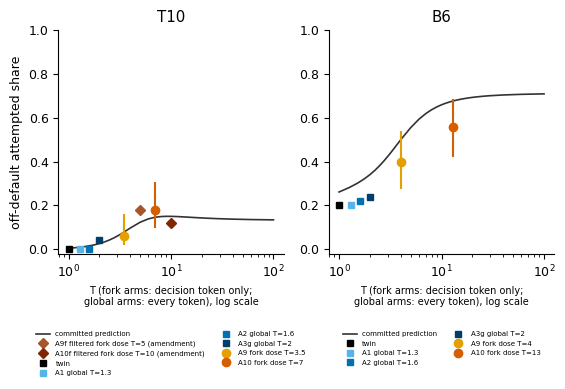

In [37]:
# ===== src/figures8.py (continued) =====
def f1(c1, cells):
    units = [u for u, e in c1["units"].items() if e.get("role") not in (None, "boundary") and u in cells]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 2.9), squeeze=False)
    for ax, u in zip(axs[0], units):
        e = c1["units"][u]
        Ts = sorted(float(t) for t in e["share_curve"])
        ax.plot(Ts, [e["share_curve"][str(t) if str(t) in e["share_curve"] else t] for t in Ts], color="#333333",
                lw=1.2, label="committed prediction")
        for a, T in (("A9", e["dose"]["d1"]), ("A10", e["dose"]["d2"])):
            if a in cells[u]:
                c = cells[u][a]
                x = round(c["off_default_attempted"] * c["n"])
                lo, hi = PR.wilson(x, c["n"])
                ax.errorbar([T], [c["off_default_attempted"]], yerr=[[c["off_default_attempted"] - lo],
                                                                     [hi - c["off_default_attempted"]]],
                            fmt="o", color=ARM_COL[a], label=f"{a} fork dose T={T:g}")
        c3p = PRED_DIR / "commit3_amendment.json"
        if c3p.exists():
            e3 = read_json(c3p)["units"].get(u)
            for a in ("A9f", "A10f"):
                if e3 and a in cells[u]:
                    T = e3["arms"][a]["T"]
                    c = cells[u][a]
                    ax.plot([T], [c["off_default_attempted"]], "D", color=ARM_COL[a], ms=5,
                            label=f"{a} filtered fork dose T={T:g} (amendment)")
        for a, T in (("A0", 1.0), ("A1", 1.3), ("A2", 1.6), ("A3g", 2.0)):
            if a in cells[u]:
                ax.plot([T], [cells[u][a]["off_default_attempted"]], "s", color=ARM_COL[a], ms=5,
                        label=f"{a} global T={T:g}" if a != "A0" else "twin")
        ax.set_xscale("log")
        ax.set_title(u)
        ax.set_xlabel("T (fork arms: decision token only;\nglobal arms: every token), log scale", fontsize=7)
        ax.set_ylim(-0.02, 1.0)
        ax.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
    axs[0][0].set_ylabel("off-default attempted share")
    save(fig, "F1_dose_response")


f1(c1, cells)

### F2: quality vs diversity (K1b)

Correct-only Hill-1 against pass cost for every arm, with ellipses from `F2_BOOT` bootstrap draws. The dotted lines
are the committed criteria: Hill-1 1.8 and a cost of 5 points. The target region is the upper left.

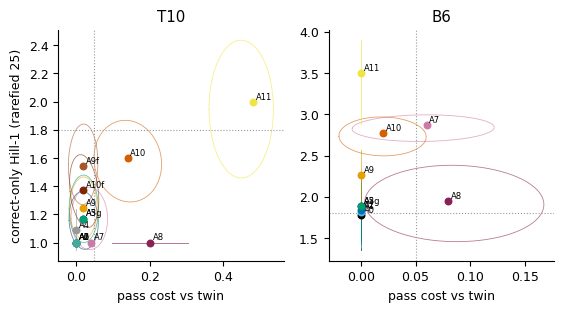

In [38]:
# ===== src/figures8.py (continued) =====
def ellipse(ax, xs, ys, col):
    if len(xs) < 5:
        return
    cov = np.cov(xs, ys)
    if not np.all(np.isfinite(cov)):
        return
    vals, vecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 80)
    circ = np.stack([np.cos(t), np.sin(t)])
    pts = vecs @ (np.sqrt(np.maximum(vals, 0))[:, None] * 2.0 * circ)
    ax.plot(np.mean(xs) + pts[0], np.mean(ys) + pts[1], color=col, lw=0.6, alpha=0.6)


def f2(data, cells):
    units = [u for u in cells if len(cells[u]) > 3]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 3.0), squeeze=False)
    rng = np.random.default_rng(7)
    for ax, u in zip(axs[0], units):
        tw = data[u]["A0"]
        slots = sorted(tw)
        for a, c in cells[u].items():
            h = c["hill1_correct_r25"]
            if h is None:
                continue
            ax.scatter([c["pass_cost"]], [h], color=ARM_COL.get(a, "#777777"), s=22, zorder=3)
            ax.annotate(a, (c["pass_cost"], h), fontsize=6, xytext=(2, 2), textcoords="offset points")
            xs, ys = [], []
            for _ in range(F2_BOOT):                 # [notebook] original: range(200)
                idx = rng.integers(0, len(slots), len(slots))
                rr = [data[u][a].get(slots[i]) for i in idx]
                if any(r is None for r in rr):
                    break
                hh = PR.hill1_rarefied([r["cls"] for r in rr if r["passed"]], 25)
                if hh is None:
                    continue
                xs.append(np.mean([tw[slots[i]]["passed"] for i in idx]) - np.mean([r["passed"] for r in rr]))
                ys.append(hh)
            ellipse(ax, np.array(xs), np.array(ys), ARM_COL.get(a, "#777777"))
        ax.axhline(1.8, ls=":", color="#999999", lw=0.8)
        ax.axvline(0.05, ls=":", color="#999999", lw=0.8)
        ax.set_title(u)
        ax.set_xlabel("pass cost vs twin")
    axs[0][0].set_ylabel("correct-only Hill-1 (rarefied 25)")
    save(fig, "F2_quality_diversity")


f2(fig_data, cells)

### F3: entropy at the decision token (K1c fails)

The plan predicted that the decision token would *not* stand out by entropy, so that entropy-based samplers would
miss it. The opposite holds. Code tokens are almost deterministic (q90 is 0.0003-0.0008 nats here), and every twin's
decision-token entropy lies far above q90.

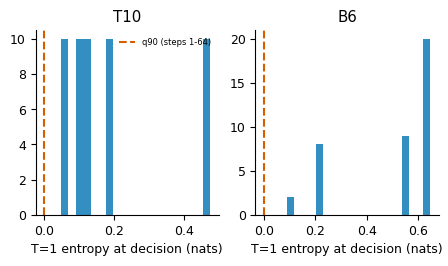

In [39]:
# ===== src/figures8.py (continued) =====
def f3(c1, data):
    units = [u for u, e in c1["units"].items() if e.get("q90") is not None and u in data]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(2.6 * len(units), 2.4), squeeze=False)
    for ax, u in zip(axs[0], units):
        H = [r["decision_H1"] for r in data[u]["A0"].values() if r.get("decision_H1") is not None]
        ax.hist(H, bins=20, color="#0072B2", alpha=0.8)
        ax.axvline(c1["units"][u]["q90"], color="#D55E00", ls="--", label="q90 (steps 1-64)")
        ax.set_title(u)
        ax.set_xlabel("T=1 entropy at decision (nats)")
    axs[0][0].legend(fontsize=6, frameon=False)
    save(fig, "F3_decision_entropy")


f3(c1, fig_data)

### F4: token maps

For each of the top-20 candidates at the node, the bars show the class shares of its 10 forced continuations. The
black line is the candidate's T = 1 mass (log10), and the red numbers are fail rates. The token map is what makes the
dose predictable: the dial can only redistribute mass among these candidates.

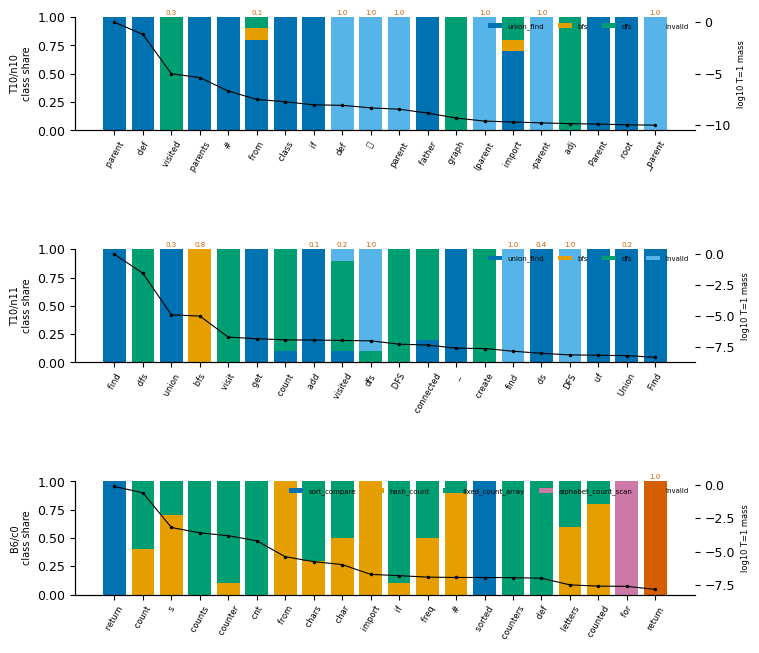

In [40]:
# ===== src/figures8.py (continued) =====
def f4(c1):
    items = []
    for u, e in c1["units"].items():
        for nd, tm in (e.get("token_map") or {}).items():
            items.append((u, nd, tm))
        if e.get("token_map_n11"):
            items.append((u, "n11", e["token_map_n11"]))
    if not items:
        return
    fig, axs = plt.subplots(len(items), 1, figsize=(8, 2.5 * len(items)), squeeze=False)
    fig.subplots_adjust(hspace=1.05)
    for ax, (u, nd, tm) in zip(axs[:, 0], items):
        info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
        toks = info["map_tokens"][:20]
        cats = UNITS[u]["catalogue"] + ["other", "invalid"]
        x = np.arange(len(toks))
        bottom = np.zeros(len(toks))
        for ci, cname in enumerate(cats):
            v = np.array([tm.get(str(t), {}).get("counts", {}).get(cname, 0) / max(tm.get(str(t), {}).get("n", 1), 1)
                          for t in toks])
            if v.sum() == 0:
                continue
            ax.bar(x, v, bottom=bottom, color=PAL[ci % len(PAL)], label=cname, width=0.8)
            bottom += v
        p1 = [info["pooled_p20"].get(str(t), 0) for t in toks]
        ax2 = ax.twinx()
        ax2.plot(x, np.log10(np.maximum(p1, 1e-12)), "k.-", lw=0.8, ms=3)
        ax2.set_ylabel("log10 T=1 mass", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(info["map_token_str"].get(str(t), "?"))[1:-1][:10] for t in toks], rotation=60,
                           fontsize=6)
        ax.set_ylabel(f"{u}/{nd}\nclass share", fontsize=7)
        ax.legend(fontsize=5, frameon=False, ncol=6, loc="upper right")
        pf = [tm.get(str(t), {}).get("pfail", 0) for t in toks]
        for xi, f in zip(x, pf):
            if f > 0:
                ax.text(xi, 1.02, f"{f:.1f}", ha="center", fontsize=5, color="#D55E00")
    save(fig, "F4_token_maps")


f4(c1)

### F5: HR branch maps

Each column is a forced rank from 1 to 64; each row is an idea. Colour shows the share of that branch's
continuations that are correct programs of the idea. The HR-only ideas sit at deep ranks.

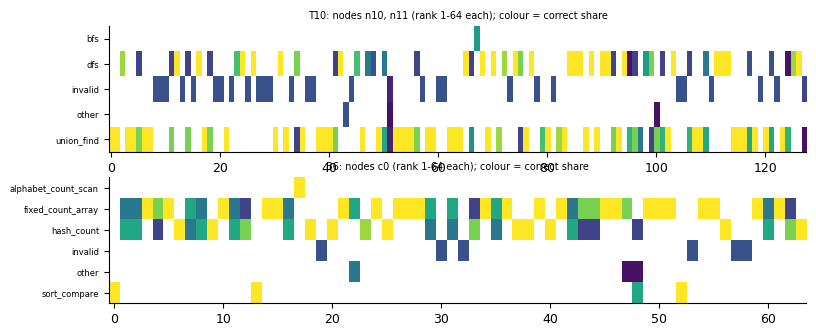

In [41]:
# ===== src/figures8.py (continued) =====
def f5(hr):
    units = list((hr or {}).get("units", {}))
    if not units:
        return
    # from cfg8 import CONT_LABELS, CONTS      [notebook] already globals
    labels = {r["sid"]: r for r in read_jsonl(CONT_LABELS)}
    fig, axs = plt.subplots(len(units), 1, figsize=(9, 1.8 * len(units)), squeeze=False)
    for ax, u in zip(axs[:, 0], units):
        rows = [r for r in read_jsonl(CONTS) if r["unit"] == u and (r.get("arm") == "HR" or
                                                                    (r.get("arm") == "MAP" and r.get("k", 9) < 5))]
        ideas = sorted({AK.cls(u, labels.get(r["sid"], {}).get("label")) for r in rows})
        nodes = sorted({r["node"] for r in rows})
        M = np.full((len(ideas), 64 * len(nodes)), np.nan)
        for ni, nd in enumerate(nodes):
            info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
            # import arms8                  [notebook] stand-in defined above
            rank_of = {t: r for r, t in arms8.hr_tokens(info)}
            for r in rows:
                if r["node"] != nd:
                    continue
                rk = r.get("rank") or rank_of.get(int(r["token"]))
                if not rk or rk > 64:
                    continue
                L = labels.get(r["sid"], {})
                i = ideas.index(AK.cls(u, L.get("label")))
                j = ni * 64 + rk - 1
                M[i, j] = (0 if np.isnan(M[i, j]) else M[i, j]) + (1.0 if L.get("passed") else 0.25) / 5
        ax.imshow(M, aspect="auto", cmap="viridis", interpolation="nearest", vmin=0, vmax=1)
        ax.set_yticks(range(len(ideas)))
        ax.set_yticklabels(ideas, fontsize=6)
        ax.set_title(f"{u}: nodes {', '.join(nodes)} (rank 1-64 each); colour = correct share", fontsize=7)
    save(fig, "F5_hr_branch_maps")


f5(hr)

### F7: CRN flip matrices

For each arm, rows are the twin's algorithm and columns the arm's algorithm, slot by slot: the same prompt with the
same random numbers. Off-diagonal mass is what the knob changed.

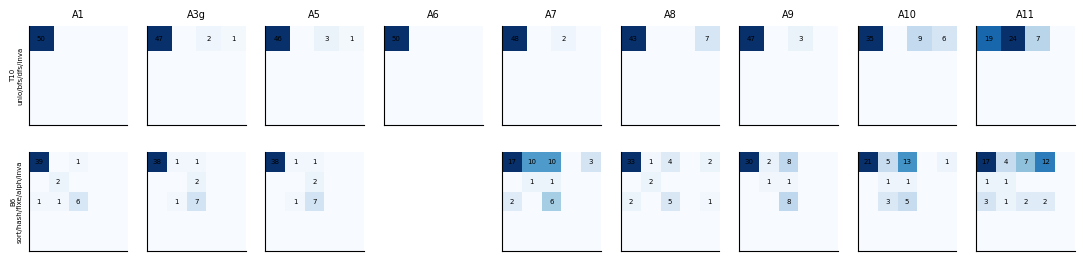

In [42]:
# ===== src/figures8.py (continued) =====
def f7(data):
    units = [u for u in data if len(data[u]) > 3]
    if not units:
        return
    arms = ["A1", "A3g", "A5", "A6", "A7", "A8", "A9", "A10", "A11"]
    fig, axs = plt.subplots(len(units), len(arms), figsize=(1.5 * len(arms), 1.5 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        cats = list(UNITS[u]["catalogue"]) + ["other", "invalid"]
        cats = [c for c in cats if any(r["cls"] == c for a in data[u] for r in data[u][a].values())]
        for j, a in enumerate(arms):
            ax = axs[i][j]
            ax.set_xticks([])
            ax.set_yticks([])
            if a not in data[u]:
                ax.axis("off")
                continue
            M = np.zeros((len(cats), len(cats)))
            for s, r in data[u][a].items():
                t = data[u]["A0"].get(s)
                if t and t["cls"] in cats and r["cls"] in cats:
                    M[cats.index(t["cls"]), cats.index(r["cls"])] += 1
            ax.imshow(M, cmap="Blues", vmin=0, vmax=max(M.max(), 1))
            for x in range(len(cats)):
                for y in range(len(cats)):
                    if M[y, x]:
                        ax.text(x, y, int(M[y, x]), ha="center", va="center", fontsize=5)
            if i == 0:
                ax.set_title(a, fontsize=7)
            if j == 0:
                ax.set_ylabel(u + "\n" + "/".join(c[:4] for c in cats), fontsize=5)
    save(fig, "F7_crn_flip_matrices")


f7(fig_data)

### F8: activation geometry, the model's own states

This is PCA of the mean **final-norm hidden state** of Qwen3-8B over the 16 positions from the decision token on, in
actual activation coordinates. It covers the twin, fork-dosed, class-forced and global-T slots; colour = the algorithm
of the program, marker = the arm. The states cluster by algorithm, and fork-dosed slots land in their own
algorithm's cluster.

A nearest-centroid check (centroids from the class-forced A11 slots) gives the share of fork-dosed slots whose state
is nearest their own class. The dial moves the model between its own existing idea-states: it stays on the manifold
and reaches no new region.

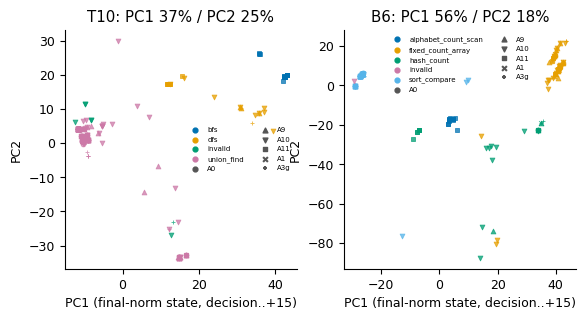

{
 "T10": {
  "explained_variance_pc1_pc2": [
   0.3679884970188141,
   0.2489595264196396
  ],
  "n_states": 300,
  "nearest_centroid_agreement_fork_dosed": 0.9042553191489362,
  "n_fork_dosed_scored": 94,
  "centroid_classes": [
   "bfs",
   "dfs",
   "union_find"
  ]
 },
 "B6": {
  "explained_variance_pc1_pc2": [
   0.5634384751319885,
   0.1798793226480484
  ],
  "n_states": 233,
  "nearest_centroid_agreement_fork_dosed": 0.8311688311688312,
  "n_fork_dosed_scored": 77,
  "centroid_classes": [
   "alphabet_count_scan",
   "fixed_count_array",
   "hash_count",
   "sort_compare"
  ]
 }
}


In [43]:
# ===== src/figures8.py (continued) =====
def f8(data):
    """PCA of the mean final-norm hidden state over the 16 positions from the decision token."""
    H: dict[str, np.ndarray] = {}            # sid -> state (Qwen 4096-d, Gemma 2560-d: never mixed in one PCA)
    for f in sorted(glob.glob(str(CACHE_DIR / "hid" / "*.npz"))):
        z = np.load(f, allow_pickle=False)
        for s_, v in zip(z["sids"], z["H"]):
            H[str(s_)] = v.astype(np.float32)
    if not H:
        return {}
    idx = {s: s for s in H}
    out = {}
    units = [u for u in ("T10", "B3", "A3", "B6", "G", "T1") if u in data]
    fig, axs = plt.subplots(1, len(units), figsize=(3.3 * len(units), 3.1), squeeze=False)
    for ax, u in zip(axs[0], units):
        rows = [(a, r) for a in ("A0", "A9", "A10", "A11", "A1", "A3g") if a in data[u] for r in data[u][a].values()
                if r["sid"] in idx]
        if len(rows) < 10:
            ax.axis("off")
            continue
        X = np.stack([H[idx[r["sid"]]] for _, r in rows])
        mu = X.mean(0)
        U_, S_, Vt = np.linalg.svd(X - mu, full_matrices=False)
        ev = (S_ ** 2) / np.sum(S_ ** 2)
        P = (X - mu) @ Vt[:2].T
        cats = sorted({r["cls"] for _, r in rows})
        mk = {"A0": "o", "A9": "^", "A10": "v", "A11": "s", "A1": "x", "A3g": "+"}
        for (a, r), p in zip(rows, P):
            ax.scatter(p[0], p[1], marker=mk[a], s=12, color=PAL[cats.index(r["cls"]) % len(PAL)], alpha=0.75,
                       linewidths=0.6)
        for ci, c in enumerate(cats):
            ax.scatter([], [], color=PAL[ci % len(PAL)], label=c, s=12)
        for a, m in mk.items():
            ax.scatter([], [], marker=m, color="#555555", label=a, s=12)
        ax.set_title(f"{u}: PC1 {ev[0]:.0%} / PC2 {ev[1]:.0%}")
        ax.set_xlabel("PC1 (final-norm state, decision..+15)")
        ax.set_ylabel("PC2")
        ax.legend(fontsize=5, frameon=False, ncol=2)
        # nearest-centroid on-manifold check: centroids from class-forced (A11) slots by program label
        cent = {}
        for c in cats:
            pts = [H[idx[r["sid"]]] for a, r in rows if a == "A11" and r["cls"] == c]
            if len(pts) >= 2:
                cent[c] = np.mean(pts, 0)
        agree = n = 0
        for a, r in rows:
            if a in ("A9", "A10") and cent and r["cls"] in cent:
                d = {c: np.linalg.norm(H[idx[r["sid"]]] - v) for c, v in cent.items()}
                agree += int(min(d, key=d.get) == r["cls"])
                n += 1
        out[u] = {"explained_variance_pc1_pc2": ev[:2].tolist(), "n_states": len(rows),
                  "nearest_centroid_agreement_fork_dosed": agree / n if n else None, "n_fork_dosed_scored": n,
                  "centroid_classes": sorted(cent)}
    save(fig, "F8_activation_geometry")
    return out


geo = f8(fig_data)
write_json(RESULTS_DIR / "geometry_f8.json", geo)
print(json.dumps(geo, indent=1))

## Results summary: recomputed in this notebook vs the original run

Every headline number of the two units, recomputed above from the shipped rows, next to the artifact's stored
results. They match at the original configuration (`N_BOOT = 2000`); at a smaller `N_BOOT` only the bootstrap rows
differ. The plot shows K1(a): each point is one algorithm class in one fork-dosed cell, with its committed prediction
against the observed share.

**Reading.** Temperature concentrated on the decision token is a precise, predictable dial *between algorithms the
model already has*:
- On the mixed unit B6 it raises correct diversity well beyond every sampling knob.
- On the collapsed unit T10 it reaches DFS where global temperature cannot, but only a little, and at a cost in
  broken programs.
- Forcing the top-64 branches (HR) adds one more *known* idea per unit: BFS on T10, about 2 × 10^6 T = 1 samples away,
  and an alphabet-scan counter on B6, about 4 × 10^7 away. It reaches no novel algorithm.

,unit,quantity,recomputed,original run,match
0,T10,dose d1 / d2,3.5 / 7,3.5 / 7,yes
1,T10,K1a MAE composed prediction,0.017,0.017,yes
2,T10,K1a MAE per-slot replay,0.013,0.013,yes
3,T10,A0 correct Hill-1,1.0,1.0,yes
4,T10,A3g correct Hill-1,1.17,1.17,yes
5,T10,A9 correct Hill-1,1.243,1.243,yes
6,T10,A10 correct Hill-1,1.602,1.602,yes
7,T10,A11 correct Hill-1,1.995,1.995,yes
8,T10,A10 pass rate,0.86,0.86,yes
9,T10,A10 off-default attempted share,0.18,0.18,yes


32 / 32 recomputed values equal the original run


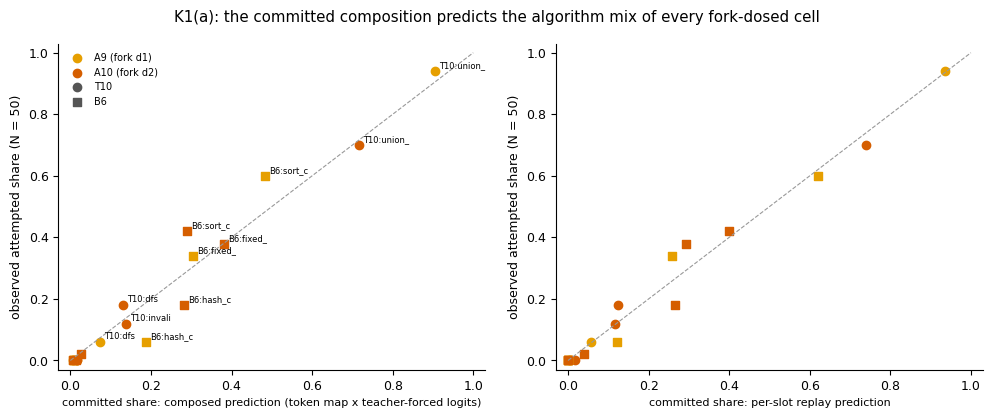

In [44]:
# [notebook] recomputed (this run) vs stored (the original artifact's results/*.json)
amend_res = read_json(RESULTS_DIR / "amendment.json")
def _r(x, n=3):
    return round(x, n) if isinstance(x, float) else x
S = []
def add(u, q, mine, stored):
    S.append({"unit": u, "quantity": q, "recomputed": _r(mine), "original run": _r(stored),
              "match": "yes" if (_r(mine, 6) == _r(stored, 6)) else "differs"})
for u in UNITS_TO_RUN:
    rc, rv = ref["k1_cells"][u], ref["k1_verdict"]
    alt = "dfs" if u == "T10" else None
    add(u, "dose d1 / d2", f'{tab["units"][u]["dose"]["d1"]:g} / {tab["units"][u]["dose"]["d2"]:g}',
        f'{ref["commit1"][u]["dose"]["d1"]:g} / {ref["commit1"][u]["dose"]["d2"]:g}')
    add(u, "K1a MAE composed prediction", v["K1a"]["per_unit"][u]["mae"], rv["K1a"][u]["mae"])
    add(u, "K1a MAE per-slot replay", v["K1a"]["per_unit"][u]["mae_replay"], rv["K1a"][u]["mae_replay"])
    for a in ("A0", "A3g", "A9", "A10", "A11"):
        add(u, f"{a} correct Hill-1", v["cells"][u][a]["hill1_correct_r25"], rc[a]["hill1_correct_r25"])
    add(u, "A10 pass rate", v["cells"][u]["A10"]["pass_rate"], rc["A10"]["pass_rate"])
    add(u, "A10 off-default attempted share", v["cells"][u]["A10"]["off_default_attempted"], rc["A10"]["off_default_attempted"])
    bs, bs0 = v["K1b"]["per_unit"][u]["bootstrap"]["best_comparator"], rv["K1b"][u]["bootstrap"]["best_comparator"]
    add(u, "bootstrap: fork - best comparator, 97.5% LB", bs["lb_97_5"], bs0["lb_97_5"])
    add(u, "bootstrap: one-sided p", bs["p_one_sided"], bs0["p_one_sided"])
    if u in v["secondary_mcnemar_A10_vs_A3g"]:
        m_, m0 = v["secondary_mcnemar_A10_vs_A3g"][u], rv["secondary_mcnemar_A10_vs_A3g"][u]
        add(u, "McNemar A10 vs global T 2.0 (b:c, p)", f'{m_["b_A10_only"]}:{m_["c_A3g_only"]}, p={m_["p_one_sided"]:.3f}',
            f'{m0["b_A10_only"]}:{m0["c_A3g_only"]}, p={m0["p_one_sided"]:.3f}')
    if u in amend_res["units"]:
        x, x0 = amend_res["units"][u], ref["amendment"][u]
        add(u, "amendment A9f pass rate / Hill-1", f'{x["cells"]["A9f"]["pass_rate"]:.2f} / {x["cells"]["A9f"]["hill1_correct_r25"]:.2f}',
            f'{x0["cells"]["A9f"]["pass_rate"]:.2f} / {x0["cells"]["A9f"]["hill1_correct_r25"]:.2f}')
    add(u, "HR-only ideas", ", ".join(hr_res["units"][u]["HR_only"]), ", ".join(ref["hr"][u]["HR_only"]))
    for idea in hr_res["units"][u]["HR_only"]:
        add(u, f"{idea}: expected T=1 samples to see once", f'{hr_res["units"][u]["reachability"][idea]["expected_T1_samples"]:.2e}',
            f'{ref["hr"][u]["reachability"][idea]["expected_T1_samples"]:.2e}')
    add(u, "F8 nearest-centroid agreement (fork-dosed)", geo[u]["nearest_centroid_agreement_fork_dosed"],
        ref["geometry_f8"][u]["nearest_centroid_agreement_fork_dosed"])
summary = pd.DataFrame(S)
display(summary)
print(f'{(summary["match"] == "yes").sum()} / {len(summary)} recomputed values equal the original run')

# K1(a) at a glance: committed prediction vs observed attempted share, per class, fork-dosed cells
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
mk = {"T10": "o", "B6": "s"}
for u in UNITS_TO_RUN:
    e = tab["units"][u]
    for a, col in (("A9", "#E69F00"), ("A10", "#D55E00")):
        obs = v["cells"][u][a]["attempted"]
        for c_ in e["classes"]:
            if max(obs.get(c_, 0), e["arms"][a]["attempted"][c_]) < 0.005:
                continue
            axs[0].scatter(e["arms"][a]["attempted"][c_], obs.get(c_, 0), marker=mk.get(u, "o"), color=col, s=36)
            if max(obs.get(c_, 0), e["arms"][a]["attempted"][c_]) >= 0.05:
                axs[0].annotate(f"{u}:{c_[:6]}", (e["arms"][a]["attempted"][c_], obs.get(c_, 0)), fontsize=6,
                                xytext=(3, 2), textcoords="offset points")
            axs[1].scatter(e["arms"][a]["replay"]["attempted"][c_], obs.get(c_, 0), marker=mk.get(u, "o"), color=col, s=36)
for ax, t in zip(axs, ("composed prediction (token map x teacher-forced logits)", "per-slot replay prediction")):
    ax.plot([0, 1], [0, 1], color="#999999", ls="--", lw=0.8)
    ax.set_xlabel(f"committed share: {t}", fontsize=8)
    ax.set_ylabel("observed attempted share (N = 50)")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
for a, col in (("A9 (fork d1)", "#E69F00"), ("A10 (fork d2)", "#D55E00")):
    axs[0].scatter([], [], color=col, label=a)
for u in UNITS_TO_RUN:
    axs[0].scatter([], [], color="#555555", marker=mk.get(u, "o"), label=u)
axs[0].legend(fontsize=7, frameon=False)
fig.suptitle("K1(a): the committed composition predicts the algorithm mix of every fork-dosed cell")
plt.tight_layout()
plt.show()